# Quantum Kernel Methods for Imbalanced Fraud Detection

Fidelity and projected quantum kernels, simulated in NumPy, on the ULB credit-card fraud data.

In [72]:
# - imports
import hashlib
import json
import os
import time
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector, partial_trace
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import fake_provider
from scipy.stats import wilcoxon
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, OneClassSVM


In [73]:
# - all the settings in one place, change things here
SETTINGS = {
    "dataset": "ulb",
    "raw_file": "data/raw/ulb/creditcard.csv",
    "clean_file": "data/clean/ulb.parquet",
    "prepared_dir": "data/prepared",
    "seed": 42,
    "test_fraction": 0.2,
    "n_repeats": 5,
    "n_train": 5000,  # all training frauds plus random legit rows
    "q_values": [2, 4, 6, 8],
    "min_frauds": 10,
    "results_file": "results/quantum_kernel_svm/quantum_kernel_svm.csv",
    "cv_folds": 4,
    "C_values": [0.1, 1, 10],
    "gamma_factors": [0.1, 0.3, 1, 3],
    "nu_values": [0.001, 0.01, 0.05],
    "reps": 2,
    "bandwidth": 1.0,
    "feature_maps": ["zz", "iqp"],
    "bandwidths": [0.1, 0.2, 0.5, 1.0],
    "RUN_SWEEP": True,
    "sweep": {"n_seeds": 1, "q_values": [2, 4]},  # full grid: {"n_seeds": 5, "q_values": [2, 4, 6, 8]}
    "extra_q": {"n_seeds": 1, "q_values": [10]},  # bigger q on fewer seeds, add 12 if you have hours to spare
    "diag_n": 1000,
    "diag_q_values": [2, 4, 6, 8, 10, 12],
    "diag_feature_maps": ["zz", "iqp", "iqpnn"],  # iqpnn: IQP phases on the ZZ neighbour-only layout
    "spectrum_c": [0.2, 1.0],
    "run_diagnostics": True,
    "diagnostics_file": "results/quantum_kernel_svm/kernel_diagnostics.csv",
    "RUN_SHOTS": True,
    "shots": [100, 1000, 10000],
    "shots_file": "results/quantum_kernel_svm/shots.csv",
    "backend": "FakeTorino",
    "RUN_NOISY": True,
    "noisy": {"q": 4, "n_train_fraud": 30, "n_train_legit": 90, "n_test_fraud": 30, "n_test_legit": 300,
              "shots": 1000},
    "noisy_file": "results/quantum_kernel_svm/noisy.csv",
    "learning_sizes": [2500, 5000, 10000],  # training sizes for section 12, seed 42 only
    "fraud_weights": [1, 3, "balanced"],  # weight of a fraud vs a legit row in the SVM, "balanced" is about 12
    "target_recall": 0.8,
    "RUN_MORE_DATA": True,
    "more_data_file": "results/quantum_kernel_svm/more_data.csv",
    "kernel_chunk": 2000,
    # change this text whenever the method changes, so old runs in the results file are not reused
    "design": "v3: all train frauds, full test split, preprocessing inside CV, weighted CV AP, gamma from feature spread, batched test scoring",
    "example": {"q": 4, "feature_map": "zz", "c": 0.5, "n_legit": 300, "n_fraud": 60},
    "colors": {"legit": "#2a78d6", "fraud": "#eb6834"},
}

## 1. Data

Load the data, have a quick look, drop exact duplicates and save a clean copy.

In [74]:
# - load the raw csv and make sure the columns look right
df = pd.read_csv(SETTINGS["raw_file"])
with open(SETTINGS["raw_file"], "rb") as f:
    DATA_SHA1 = hashlib.sha1(f.read()).hexdigest()[:12]

expected_columns = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
assert list(df.columns) == expected_columns
assert set(df["Class"].unique()) == {0, 1}
print(df.shape)

(284807, 31)


In [75]:
# - how many rows, frauds and duplicates there are
n_rows = len(df)
n_fraud = df["Class"].sum()
duplicated = df.duplicated()

print(f"{n_rows:,} rows, {n_fraud:,} frauds ({n_fraud / n_rows:.3%})")
print(f"{duplicated.sum():,} duplicate rows, {df.loc[duplicated, 'Class'].sum()} of them fraud")

284,807 rows, 492 frauds (0.173%)
1,081 duplicate rows, 19 of them fraud


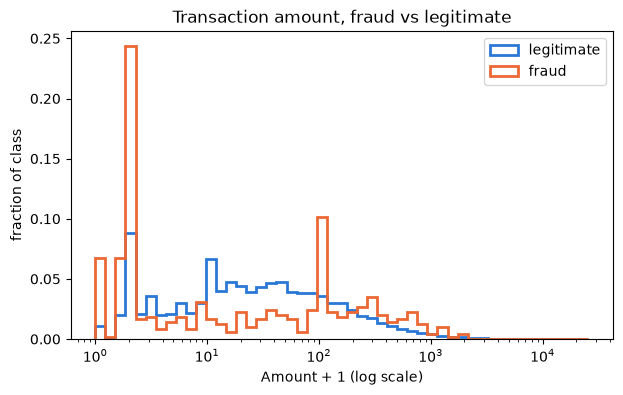

In [76]:
# - amount distribution for fraud vs legit
fraud = df["Class"] == 1
bins = np.logspace(0, np.log10(df["Amount"].max() + 1), 50)

plt.figure(figsize=(7, 4))
for is_fraud, label, color in [(False, "legitimate", "legit"), (True, "fraud", "fraud")]:
    amounts = df.loc[fraud == is_fraud, "Amount"] + 1
    weights = np.ones(len(amounts)) / len(amounts)
    plt.hist(amounts, bins=bins, weights=weights, histtype="step", linewidth=2,
             color=SETTINGS["colors"][color], label=label)
plt.xscale("log")
plt.xlabel("Amount + 1 (log scale)")
plt.ylabel("fraction of class")
plt.title("Transaction amount, fraud vs legitimate")
plt.legend()
plt.show()

V14    0.449
V4     0.438
V12    0.437
V11    0.418
V10    0.414
dtype: float64


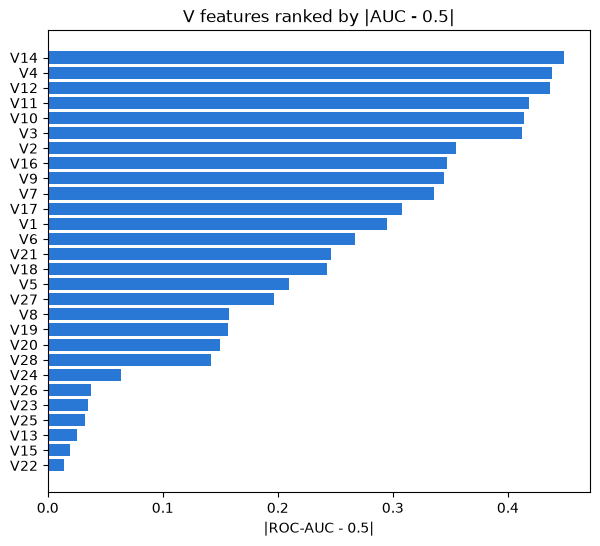

In [77]:
# - rough idea of which V columns separate fraud from legit
v_features = [f"V{i}" for i in range(1, 29)]
separation = {}
for col in v_features:
    auc = roc_auc_score(df["Class"], df[col])
    separation[col] = abs(auc - 0.5)
ranking = pd.Series(separation).sort_values(ascending=False)
print(ranking.head(5).round(3))

plt.figure(figsize=(7, 6))
plt.barh(ranking.index[::-1], ranking.values[::-1], color=SETTINGS["colors"]["legit"])
plt.xlabel("|ROC-AUC - 0.5|")
plt.title("V features ranked by |AUC - 0.5|")
plt.show()

This ranking uses every row, so it's only for getting a feel for the data. Nothing later is picked from it.

In [78]:
# - drop exact duplicate rows (outliers stay)
clean = df.drop_duplicates().reset_index(drop=True)

print(f"dropped {n_rows - len(clean):,} duplicates ({n_fraud - clean['Class'].sum()} were fraud)")
print(f"left with {len(clean):,} rows and {clean['Class'].sum()} frauds ({clean['Class'].mean():.3%})")

dropped 1,081 duplicates (19 were fraud)
left with 283,726 rows and 473 frauds (0.167%)


In [79]:
# - save the cleaned data
os.makedirs(os.path.dirname(SETTINGS["clean_file"]), exist_ok=True)
clean.to_parquet(SETTINGS["clean_file"], index=False)

assert pd.read_parquet(SETTINGS["clean_file"]).equals(clean)
print("saved to", SETTINGS["clean_file"])

saved to data/clean/ulb.parquet


### Where the frauds are

A few plots on how rare fraud is and how it differs from normal transactions. They're only for looking; no model uses them.

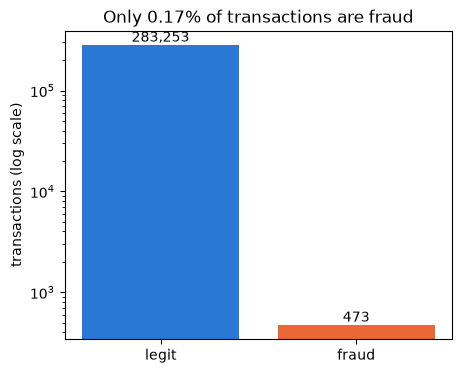

In [80]:
# - how rare fraud is
counts = clean["Class"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
bars = plt.bar(["legit", "fraud"], counts.values, color=[SETTINGS["colors"]["legit"], SETTINGS["colors"]["fraud"]])
plt.bar_label(bars, labels=[f"{n:,}" for n in counts.values])
plt.yscale("log")
plt.ylabel("transactions (log scale)")
plt.title(f"Only {counts[1] / counts.sum():.2%} of transactions are fraud")
plt.show()

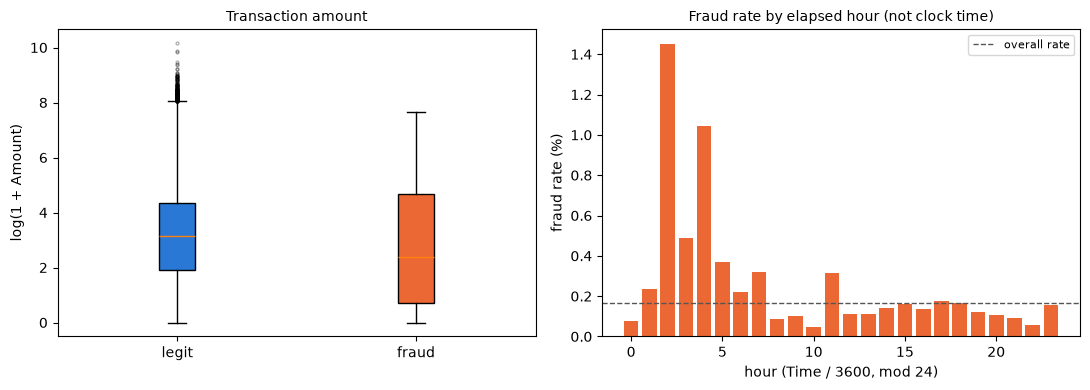

In [81]:
# - amount and time of day for each class
is_fraud = (clean["Class"] == 1).to_numpy()
hour = (clean["Time"] // 3600) % 24

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
box = axes[0].boxplot([np.log1p(clean.loc[~is_fraud, "Amount"]), np.log1p(clean.loc[is_fraud, "Amount"])],
                      tick_labels=["legit", "fraud"], patch_artist=True, flierprops={"markersize": 2, "alpha": 0.3})
for patch, label in zip(box["boxes"], ["legit", "fraud"]):
    patch.set_facecolor(SETTINGS["colors"][label])
axes[0].set_ylabel("log(1 + Amount)")
axes[0].set_title("Transaction amount", fontsize=10)

rate = clean.groupby(hour)["Class"].mean() * 100
axes[1].bar(rate.index, rate.values, color=SETTINGS["colors"]["fraud"])
axes[1].axhline(clean["Class"].mean() * 100, color="#555555", linestyle="--", linewidth=1, label="overall rate")
axes[1].set_xlabel("hour (Time / 3600, mod 24)")
axes[1].set_ylabel("fraud rate (%)")
axes[1].set_title("Fraud rate by elapsed hour (not clock time)", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

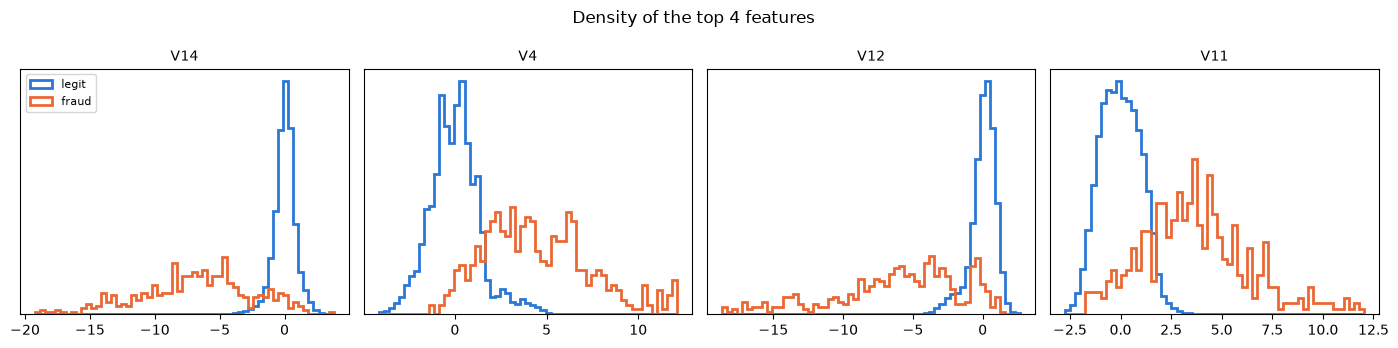

In [82]:
# - the 4 V features that separate the classes best, fraud vs legit
top = ranking.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, top):
    values = clean[col]
    bins = np.linspace(min(values.quantile(0.001), values[is_fraud].min()),
                       max(values.quantile(0.999), values[is_fraud].max()), 60)
    for label, mask in [("legit", ~is_fraud), ("fraud", is_fraud)]:
        ax.hist(values[mask], bins=bins, density=True, histtype="step", linewidth=2,
                color=SETTINGS["colors"][label], label=label)
    ax.set_title(col, fontsize=10)
    ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle("Density of the top 4 features")
fig.tight_layout()
plt.show()

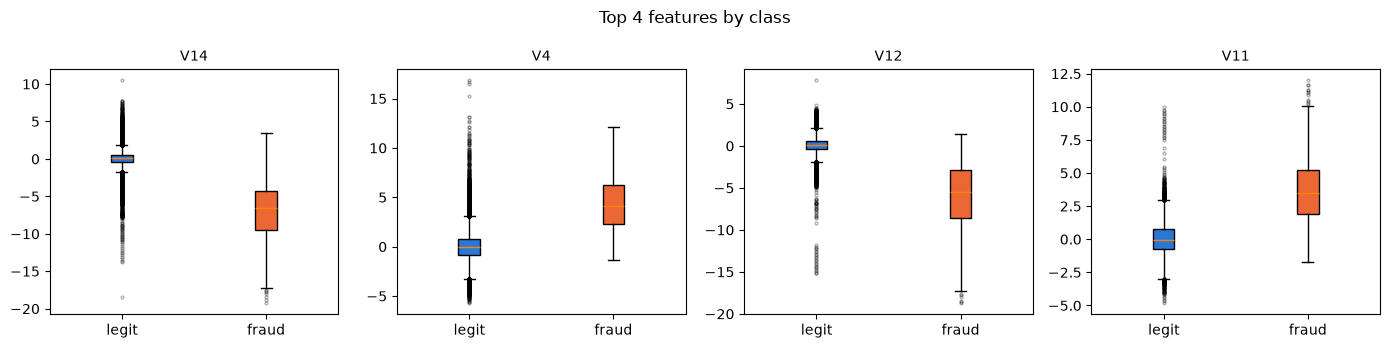

In [83]:
# - same 4 features as box plots, the dots are outliers
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, top):
    box = ax.boxplot([clean.loc[~is_fraud, col], clean.loc[is_fraud, col]], tick_labels=["legit", "fraud"],
                     patch_artist=True, flierprops={"markersize": 2, "alpha": 0.3})
    for patch, label in zip(box["boxes"], ["legit", "fraud"]):
        patch.set_facecolor(SETTINGS["colors"][label])
    ax.set_title(col, fontsize=10)
fig.suptitle("Top 4 features by class")
fig.tight_layout()
plt.show()

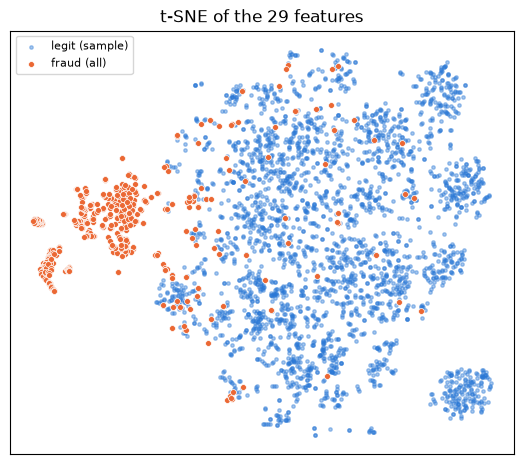

In [84]:
# - t-SNE map of all frauds and 3000 random legit rows
rng = np.random.default_rng(SETTINGS["seed"])
sample_rows = np.r_[rng.choice(np.where(~is_fraud)[0], 3000, replace=False), np.where(is_fraud)[0]]
features = clean.iloc[sample_rows].drop(columns=["Time", "Class"])
features["Amount"] = np.log1p(features["Amount"])
embedding = TSNE(n_components=2, init="pca", random_state=SETTINGS["seed"]).fit_transform(
    StandardScaler().fit_transform(features))
y_sample = is_fraud[sample_rows]

plt.figure(figsize=(6.5, 5.5))
plt.scatter(*embedding[~y_sample].T, s=6, alpha=0.4, color=SETTINGS["colors"]["legit"], label="legit (sample)")
plt.scatter(*embedding[y_sample].T, s=18, color=SETTINGS["colors"]["fraud"], edgecolor="white", linewidth=0.5,
            label="fraud (all)")
plt.xticks([])
plt.yticks([])
plt.title("t-SNE of the 29 features")
plt.legend(fontsize=8)
plt.show()

## 2. Splits and features

One train/test split. Each seed's training sample keeps every training fraud plus random legit rows, and the test set is the whole test split at the real fraud rate. Only raw features are saved; scaling, PCA and angle encoding are fitted later on training rows only, inside every CV fold too.

In [85]:
# - one stratified train/test split
y_all = clean["Class"].to_numpy()
idx_all = np.arange(len(clean))

idx_train_full, idx_test_full = train_test_split(
    idx_all, test_size=SETTINGS["test_fraction"], stratify=y_all, random_state=SETTINGS["seed"]
)
print(f"train: {len(idx_train_full):,} rows, {y_all[idx_train_full].sum()} frauds")
print(f"test:  {len(idx_test_full):,} rows, {y_all[idx_test_full].sum()} frauds")

train: 226,980 rows, 378 frauds
test:  56,746 rows, 95 frauds


In [86]:
# - training samples: every training fraud plus random legit rows, one sample per seed
def training_sample(seed, n_train=None):
    n_train = n_train or SETTINGS["n_train"]
    frauds = idx_train_full[y_all[idx_train_full] == 1]
    legit_pool = idx_train_full[y_all[idx_train_full] == 0]
    legit = np.random.default_rng(seed).choice(legit_pool, n_train - len(frauds), replace=False)
    return np.sort(np.r_[frauds, legit])


TRUE_FRAUD_RATE = y_all[idx_train_full].mean()
seeds = [SETTINGS["seed"] + r for r in range(SETTINGS["n_repeats"])]
train_samples = {s: training_sample(s) for s in seeds}
SPLIT_SHA1 = hashlib.sha1(np.concatenate([*train_samples.values(), idx_test_full]).tobytes()).hexdigest()[:12]

In [87]:
# - raw features: drop Time, log of Amount (no scaling here, that is fitted per fold later)
def raw_features(rows):
    X = rows.drop(columns=["Time", "Class"])
    X["Amount"] = np.log1p(X["Amount"])
    return X.to_numpy()

In [88]:
# - save the raw arrays for every seed, plus the other training sizes for section 12
def prepared_path(seed, n_train=None):
    if n_train is None or n_train == SETTINGS["n_train"]:
        return os.path.join(SETTINGS["prepared_dir"], f"{SETTINGS['dataset']}_seed{seed}.npz")
    return os.path.join(SETTINGS["prepared_dir"], f"{SETTINGS['dataset']}_seed{seed}_n{n_train}.npz")


def save_prepared(path, idx):
    np.savez(path, X_train=X_all[idx], y_train=y_all[idx], X_test=X_all[idx_test_full],
             y_test=y_all[idx_test_full], idx_train=idx, idx_test=idx_test_full)


os.makedirs(SETTINGS["prepared_dir"], exist_ok=True)
X_all = raw_features(clean)
for s, idx in train_samples.items():
    save_prepared(prepared_path(s), idx)
for n in SETTINGS["learning_sizes"]:
    save_prepared(prepared_path(SETTINGS["seed"], n), training_sample(SETTINGS["seed"], n))
print("saved arrays to", SETTINGS["prepared_dir"])

saved arrays to data/prepared


In [89]:
# - every model loads its data through this
def load_prepared(seed, n_train=None):
    data = np.load(prepared_path(seed, n_train))
    return data["X_train"], data["y_train"], data["X_test"], data["y_test"]

In [90]:
# - count frauds in each split, warn if there are too few
rows = []
for s in seeds:
    X_train, y_train, X_test, y_test = load_prepared(s)
    rows.append({"seed": s, "n_train": len(y_train), "frauds_train": y_train.sum(),
                 "n_test": len(y_test), "frauds_test": y_test.sum()})
fraud_table = pd.DataFrame(rows).set_index("seed")
print(fraud_table)

for s, row in fraud_table.iterrows():
    for part in ["train", "test"]:
        if row[f"frauds_{part}"] < SETTINGS["min_frauds"]:
            print(f"careful: seed {s} has only {row[f'frauds_{part}']} frauds in {part}, PR-AUC will be noisy")

      n_train  frauds_train  n_test  frauds_test
seed                                            
42       5000           378   56746           95
43       5000           378   56746           95
44       5000           378   56746           95
45       5000           378   56746           95
46       5000           378   56746           95


In [91]:
# - sanity checks on the saved files (no overlap, all frauds kept, test at the real rate)
n_train_frauds = y_all[idx_train_full].sum()
for s in seeds:
    d = np.load(prepared_path(s))
    assert len(np.intersect1d(d["idx_train"], d["idx_test"])) == 0, "row in both train and test"
    assert np.array_equal(d["y_train"], y_all[d["idx_train"]]) and np.array_equal(d["y_test"], y_all[d["idx_test"]])
    assert len(d["y_train"]) == SETTINGS["n_train"] and d["y_train"].sum() == n_train_frauds
    assert set(d["idx_train"]) <= set(idx_train_full) and np.array_equal(d["idx_test"], idx_test_full)
    assert d["X_train"].shape == (SETTINGS["n_train"], 29) and d["X_test"].shape == (len(idx_test_full), 29)
for n in SETTINGS["learning_sizes"]:
    d = np.load(prepared_path(SETTINGS["seed"], n))
    assert len(d["y_train"]) == n and d["y_train"].sum() == n_train_frauds
    assert set(d["idx_train"]) <= set(idx_train_full) and np.array_equal(d["idx_test"], idx_test_full)
print(f"all {len(seeds)} files look ok: {n_train_frauds} frauds in every training sample "
      f"({n_train_frauds / SETTINGS['n_train']:.1%}), test fraud rate {y_all[idx_test_full].mean():.3%}")

all 5 files look ok: 378 frauds in every training sample (7.6%), test fraud rate 0.167%


## 3. Evaluation and SVM helpers

Metrics, the results file, and the CV loop shared by every quantum model. Test scores are at the real fraud rate, and CV scores are weighted back to it. The one-class SVM is fitted on legit rows only but tuned with fraud labels, so it isn't fully unsupervised.

In [92]:
# - metrics: PR-AUC, ROC-AUC and recall at 1% and 5% FPR
def recall_at_fpr(y_true, scores, max_fpr):
    fpr, tpr, _ = roc_curve(y_true, scores)
    return tpr[fpr <= max_fpr].max()


def evaluate(y_true, scores):
    return {
        "pr_auc": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        "recall_fpr1": recall_at_fpr(y_true, scores, 0.01),
        "recall_fpr5": recall_at_fpr(y_true, scores, 0.05),
    }

In [93]:
# - reading and writing the results files (quantum_kernel_svm.csv unless another file is given)
RESULT_COLUMNS = ["timestamp", "dataset", "config", "model", "q", "seed", "c", "n_train", "n_test", "params",
                  "pr_auc", "roc_auc", "recall_fpr1", "recall_fpr5"]


def config_id():
    keys = ["dataset", "seed", "test_fraction", "n_train", "reps", "cv_folds", "C_values", "gamma_factors",
            "nu_values", "design"]
    text = json.dumps({**{k: SETTINGS[k] for k in keys}, "data": DATA_SHA1, "split": SPLIT_SHA1}, sort_keys=True)
    return hashlib.sha1(text.encode()).hexdigest()[:8]


def read_results(file=None):
    file = file or SETTINGS["results_file"]
    if not os.path.exists(file):
        return pd.DataFrame(columns=RESULT_COLUMNS)
    results = pd.read_csv(file, dtype={"q": str, "seed": str, "config": str})
    if "config" not in results:
        results["config"] = "none"
    return results


def save_result(model, q, seed, params, metrics, n_train, n_test, c, file=None):
    file = file or SETTINGS["results_file"]
    row = {"timestamp": datetime.now().isoformat(timespec="seconds"), "dataset": SETTINGS["dataset"],
           "config": config_id(), "model": model, "q": str(q), "seed": str(seed), "c": c, "n_train": n_train,
           "n_test": n_test, "params": json.dumps(params), **metrics}
    old = read_results(file)
    same_run = ((old["config"] == row["config"]) & (old["model"] == model) & (old["q"] == row["q"])
                & (old["seed"] == row["seed"]) & (old["c"].astype(float).round(6) == round(c, 6)))
    table = pd.concat([old[~same_run], pd.DataFrame([row])], ignore_index=True)
    os.makedirs(os.path.dirname(file), exist_ok=True)
    table[RESULT_COLUMNS].to_csv(file, index=False)

In [94]:
# - RBF kernel by hand (in chunks, the test set is big), CV folds and a CV score at the real fraud rate
def rbf_kernel(A, B, gamma):
    K = np.empty((len(A), len(B)))
    B_squared = (B**2).sum(1)
    step = SETTINGS["kernel_chunk"]
    for start in range(0, len(A), step):
        a = A[start:start + step]
        K[start:start + step] = np.exp(-gamma * np.maximum((a**2).sum(1)[:, None] + B_squared - 2 * a @ B.T, 0))
    return K


def default_gamma(F):
    # 1 / (average squared distance between two points) / 2, from how much each feature varies across points
    spread = F.var(axis=0).sum()
    return 1 / spread if spread > 0 else 1.0


def make_folds(y):
    return list(StratifiedKFold(SETTINGS["cv_folds"], shuffle=True, random_state=SETTINGS["seed"]).split(y, y))


def validation_ap(y, scores):
    # validation folds have the enriched training fraud rate, so legit rows are weighted back to the real rate
    legit_weight = (1 - TRUE_FRAUD_RATE) / TRUE_FRAUD_RATE * (y == 1).sum() / (y == 0).sum()
    return average_precision_score(y, scores, sample_weight=np.where(y == 1, 1.0, legit_weight))

In [95]:
# - SVM and one-class SVM on precomputed kernels: tune on the CV folds, then score the test set in chunks
def kernel_input(kernel, feature_map, A):
    make = feature_states if kernel == "fidelity" else rdm_features
    return make(A, feature_map, SETTINGS["reps"])


def kernel_block(kernel, A, B, gamma):
    # fidelity inputs are feature states, projected inputs are RDM features that go through an RBF
    if kernel == "fidelity":
        return np.abs(A.conj() @ B.T) ** 2
    return rbf_kernel(A, B, gamma)


def fit_classifier(classifier, K_fit, y_fit, value):
    if classifier == "svm":
        return SVC(kernel="precomputed", C=value, class_weight="balanced").fit(K_fit, y_fit)
    legit = y_fit == 0
    return OneClassSVM(kernel="precomputed", nu=value).fit(K_fit[np.ix_(legit, legit)])


def predict(classifier, model, K_eval, y_fit):
    if classifier == "svm":
        return model.decision_function(K_eval)
    # the one-class model only knows legit rows, fraud should look odd to it, hence the minus sign
    return -model.decision_function(K_eval[:, y_fit == 0])


def tune(kernel, classifier, folds, y_train):
    factors = SETTINGS["gamma_factors"] if kernel == "projected" else [None]
    values = SETTINGS["C_values"] if classifier == "svm" else SETTINGS["nu_values"]
    best = None
    for factor in factors:
        fold_kernels = []
        for tr, va, A_fit, A_eval in folds:
            gamma = None if factor is None else factor * default_gamma(A_fit)
            fold_kernels.append((kernel_block(kernel, A_fit, A_fit, gamma), kernel_block(kernel, A_eval, A_fit, gamma)))
        for value in values:
            aps = []
            for (tr, va, _, _), (K_fit, K_eval) in zip(folds, fold_kernels):
                model = fit_classifier(classifier, K_fit, y_train[tr], value)
                aps.append(validation_ap(y_train[va], predict(classifier, model, K_eval, y_train[tr])))
            if best is None or np.mean(aps) > best[2]:
                best = (factor, value, np.mean(aps))
    return best


def run_models(kernel, feature_map, classifiers, folds, final, y_train):
    A_train, test_angles = final
    models = {}
    for clf in classifiers:
        factor, value, cv_ap = tune(kernel, clf, folds, y_train)
        gamma = None if factor is None else factor * default_gamma(A_train)
        K_train = kernel_block(kernel, A_train, A_train, gamma)
        mean, std = concentration(K_train)
        params = {"C" if clf == "svm" else "nu": value, "cv_pr_auc": cv_ap, "kernel_mean": mean, "kernel_std": std,
                  "kernel_alignment": alignment(K_train, y_train)}
        if gamma is not None:
            params["gamma"] = gamma
        models[clf] = (fit_classifier(clf, K_train, y_train, value), gamma, params)

    # test states and the test kernel are GBs at large q, so they are built one chunk of rows at a time
    scores = {clf: [] for clf in classifiers}
    step = SETTINGS["kernel_chunk"]
    for start in range(0, len(test_angles), step):
        A_test = kernel_input(kernel, feature_map, test_angles[start:start + step])
        blocks = {}
        for clf, (model, gamma, _) in models.items():
            if gamma not in blocks:
                blocks[gamma] = kernel_block(kernel, A_test, A_train, gamma)
            scores[clf].append(predict(clf, model, blocks[gamma], y_train))
    return {clf: (np.concatenate(scores[clf]), models[clf][2]) for clf in classifiers}

In [96]:
# - quick tests for the metric, the RBF kernel and the weighted CV score
assert evaluate(np.array([0, 0, 1, 1]), np.array([0.1, 0.2, 0.8, 0.9]))["pr_auc"] == 1.0
A, B = np.random.default_rng(0).normal(size=(5, 3)), np.random.default_rng(1).normal(size=(4, 3))
direct = np.exp(-0.5 * ((A[:, None, :] - B[None, :, :]) ** 2).sum(-1))
assert np.allclose(rbf_kernel(A, B, 0.5), direct)
assert np.allclose(np.diag(rbf_kernel(A, A, 0.5)), 1)
y_check = np.r_[np.zeros(50), np.ones(50)].astype(int)
scores_check = np.random.default_rng(2).normal(size=100) + y_check
assert validation_ap(y_check, scores_check) < average_precision_score(y_check, scores_check)
print("metric, kernel and weighted CV score checks passed")

metric, kernel and weighted CV score checks passed


## 4. Quantum feature map

Each data point is turned into an n-qubit state $|\phi(x)\rangle$. I simulate it in NumPy and check it against Qiskit.

All maps apply a Hadamard layer and then a diagonal phase, repeated `reps` times:
$|\phi(x)\rangle = \left(U_\Phi(x)\, H^{\otimes n}\right)^{\text{reps}} |0\rangle^{\otimes n}$, with
$U_\Phi(x)|z\rangle = \exp\!\big(2i \sum_j \phi_j z_j + 2i \sum_{(j,k)} \phi_{jk}\, (z_j \oplus z_k)\big)|z\rangle$.

- **ZZ** (neighbours only, $k = j+1$): $\phi_j = x_j$, $\phi_{jk} = (\pi - x_j)(\pi - x_k)$
- **IQP** (every pair $j < k$): $\phi_j = x_j$, $\phi_{jk} = x_j x_k$
- **IQP-nn** (neighbours only): the IQP phases on the ZZ layout, used only in the diagnostics and circuit costs

$z_j \oplus z_k$ is the $Z_j Z_k$ term up to a global phase. Before that, features are standardised, reduced to $q$ dimensions with PCA and scaled to $[0, \pi]$, all fitted on training rows only, then multiplied by the bandwidth $c$. ZZ pair phases tend to $\pi^2$ (not 0) at small $c$, so ZZ and IQP differ in their phase function as well as their connections. IQP-nn changes only the connections.

In [97]:
# - fit scaling, PCA to q dims and the angle range on training rows, then turn any rows into angles
def fit_encoder(X_train, q):
    scaler = StandardScaler().fit(X_train)
    pca = PCA(n_components=q, svd_solver="full").fit(scaler.transform(X_train))
    Z = pca.transform(scaler.transform(X_train))
    width = Z.max(axis=0) - Z.min(axis=0)
    return {"scaler": scaler, "pca": pca, "lo": Z.min(axis=0), "width": np.where(width > 0, width, 1.0)}


def encode(encoder, X, c):
    Z = encoder["pca"].transform(encoder["scaler"].transform(X))
    return c * np.clip(np.pi * (Z - encoder["lo"]) / encoder["width"], 0, np.pi)

In [98]:
# - building blocks for the statevector simulator
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


def apply_gate(state, gate, qubit, n):
    psi = np.tensordot(gate, state.reshape([2] * n), axes=([1], [qubit]))
    return np.moveaxis(psi, 0, qubit).reshape(-1)


def basis_bits(n):
    # row b = bits of |b>, qubit 0 is the leftmost (most significant) bit
    return (np.arange(2**n)[:, None] >> (n - 1 - np.arange(n))) & 1


def pairs(n, kind):
    if kind in ("zz", "iqpnn"):
        return [(i, i + 1) for i in range(n - 1)]
    return [(i, j) for i in range(n) for j in range(i + 1, n)]


def pair_angle(x, i, j, kind):
    if kind == "zz":
        return (np.pi - x[i]) * (np.pi - x[j])
    return x[i] * x[j]


def diagonal_phase(x, kind):
    n = len(x)
    z = basis_bits(n)
    angle = 2 * z @ x
    for i, j in pairs(n, kind):
        angle = angle + 2 * pair_angle(x, i, j, kind) * (z[:, i] ^ z[:, j])
    return np.exp(1j * angle)

In [99]:
# - ZZ and IQP feature states in numpy
def feature_state(x, kind, reps):
    n = len(x)
    phase = diagonal_phase(x, kind)
    state = np.zeros(2**n, dtype=complex)
    state[0] = 1
    for _ in range(reps):
        for q in range(n):
            state = apply_gate(state, H, q, n)
        state = phase * state
    return state


def zz_state(x, reps):
    return feature_state(x, "zz", reps)


def iqp_state(x, reps):
    return feature_state(x, "iqp", reps)


def feature_states(X, kind, reps):
    return np.array([feature_state(x, kind, reps) for x in X])

In [100]:
# - same feature maps as qiskit circuits
def feature_circuit(x, kind, reps):
    n = len(x)
    qc = QuantumCircuit(n)
    for _ in range(reps):
        qc.h(range(n))
        for i in range(n):
            qc.p(2 * x[i], i)
        for i, j in pairs(n, kind):
            qc.cx(i, j)
            qc.p(2 * pair_angle(x, i, j, kind), j)
            qc.cx(i, j)
    return qc


def zz_circuit(x, reps):
    return feature_circuit(x, "zz", reps)


def iqp_circuit(x, reps):
    return feature_circuit(x, "iqp", reps)

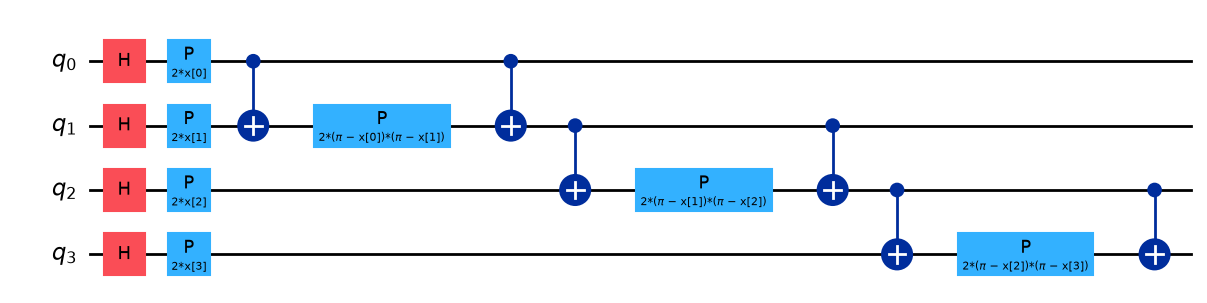

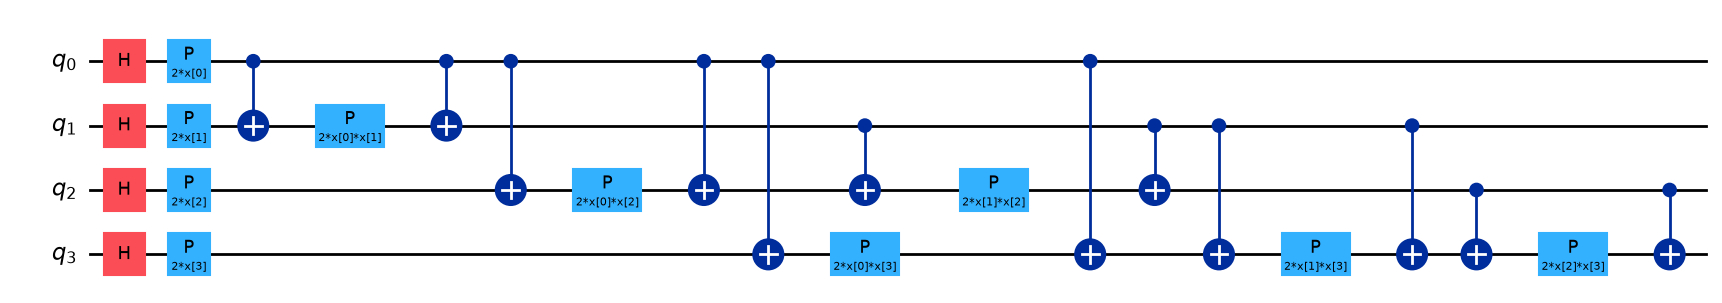

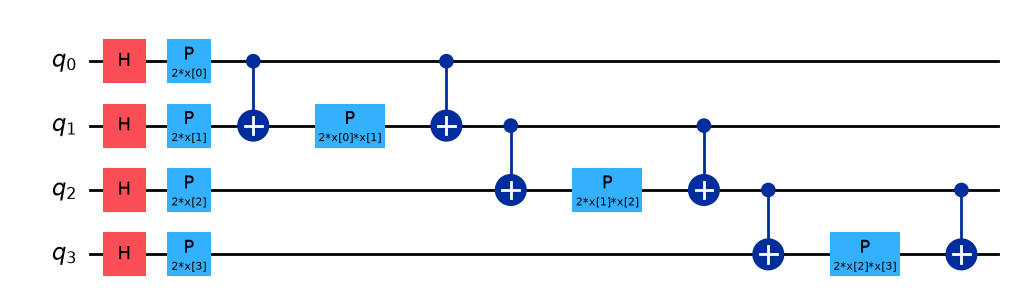

In [101]:
# - draw the circuits
x_symbols = ParameterVector("x", 4)
for feature_map in SETTINGS["diag_feature_maps"]:
    fig = feature_circuit(x_symbols, feature_map, reps=1).draw("mpl", fold=-1)
    display(fig)
    plt.close(fig)

In [102]:
# - check my states against qiskit
rng = np.random.default_rng(SETTINGS["seed"])
for n in [2, 3, 4]:
    for reps in [1, 2]:
        for _ in range(5):
            x = rng.uniform(0, np.pi, n)
            for feature_map in SETTINGS["diag_feature_maps"]:
                mine = feature_state(x, feature_map, reps)
                qiskit = Statevector(feature_circuit(x, feature_map, reps).reverse_bits()).data
                assert np.isclose(abs(np.vdot(mine, qiskit)) ** 2, 1)
                assert np.allclose(mine, qiskit)
                assert np.isclose(np.linalg.norm(mine), 1)
            library = zz_feature_map(n, reps=reps, entanglement="linear").assign_parameters(x)
            assert np.allclose(zz_state(x, reps), Statevector(library.reverse_bits()).data)

X_train, y_train, X_test, y_test = load_prepared(SETTINGS["seed"])
encoder = fit_encoder(X_train, 4)
c = SETTINGS["bandwidth"]
A_train, A_test = encode(encoder, X_train, c), encode(encoder, X_test, c)
assert A_train.min() >= 0 and A_train.max() <= c * np.pi and np.isclose(A_train.max(), c * np.pi)
assert A_test.min() >= 0 and A_test.max() <= c * np.pi
print(f"my states match qiskit for {len(SETTINGS['diag_feature_maps'])} maps on 30 random inputs")
print(f"{(A_test == 0).mean() + (A_test == c * np.pi).mean():.2%} of test angles got clipped")

my states match qiskit for 3 maps on 30 random inputs
0.01% of test angles got clipped


## 5. Fidelity kernel

$K(x, x') = |\langle \phi(x') | \phi(x) \rangle|^2$. The SVM itself is trained classically on this matrix.

In [103]:
# - fidelity kernel |<phi(x')|phi(x)>|^2, done in chunks to save memory
def fidelity_kernel(XA, XB, feature_map, reps):
    SA = feature_states(XA, feature_map, reps)
    SB = SA if XB is XA else feature_states(XB, feature_map, reps)
    K = np.empty((len(XA), len(XB)))
    step = SETTINGS["kernel_chunk"]
    for start in range(0, len(XA), step):
        K[start:start + step] = np.abs(SA[start:start + step].conj() @ SB.T) ** 2
    return K

In [104]:
# - check the kernel is symmetric, PSD and has ones on the diagonal
ex = SETTINGS["example"]
X_train, y_train, X_test, y_test = load_prepared(SETTINGS["seed"])
encoder = fit_encoder(X_train, ex["q"])
A_train, A_test = encode(encoder, X_train, ex["c"]), encode(encoder, X_test, ex["c"])

K = fidelity_kernel(A_train[:1000], A_train[:1000], ex["feature_map"], SETTINGS["reps"])
assert np.allclose(np.diag(K), 1)
assert np.allclose(K, K.T)
assert K.min() >= 0 and K.max() <= 1 + 1e-12
assert np.linalg.eigvalsh(K).min() > -1e-8

K_chunked = fidelity_kernel(A_test[:4500], A_train[:50], ex["feature_map"], SETTINGS["reps"])
S_test, S_train = feature_states(A_test[:4500], ex["feature_map"], SETTINGS["reps"]), feature_states(A_train[:50], ex["feature_map"], SETTINGS["reps"])
assert np.allclose(K_chunked, np.abs(S_test.conj() @ S_train.T) ** 2)
print(f"kernel looks fine, smallest eigenvalue {np.linalg.eigvalsh(K).min():.1e}")

kernel looks fine, smallest eigenvalue -1.1e-13


On real hardware the kernel comes from the circuit $U(x')^\dagger U(x)$: the chance of measuring $|0\dots0\rangle$ is $K(x, x')$.

K(x, x') = 0.8728   P(|0000>) = 0.8728   from 1000 shots: 0.874


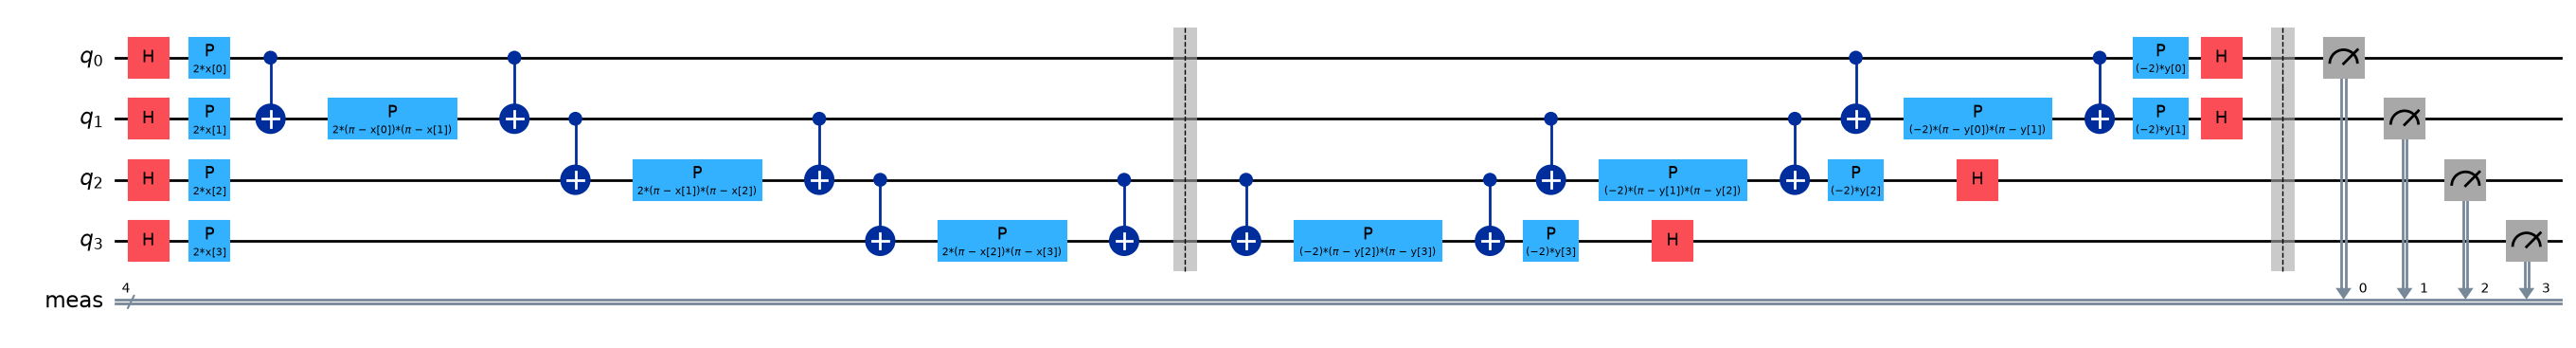

In [105]:
# - compute-uncompute circuit: P(0...0) should equal the kernel value
x, x_prime = A_train[0], A_train[1]
qc = feature_circuit(x, ex["feature_map"], SETTINGS["reps"])
qc.compose(feature_circuit(x_prime, ex["feature_map"], SETTINGS["reps"]).inverse(), inplace=True)

state = Statevector(qc)
p_zero = state.probabilities()[0]
k = fidelity_kernel(x[None], x_prime[None], ex["feature_map"], SETTINGS["reps"])[0, 0]
assert np.isclose(p_zero, k)

state.seed(SETTINGS["seed"])
counts = state.sample_counts(1000)
print(f"K(x, x') = {k:.4f}   P(|0000>) = {p_zero:.4f}   from 1000 shots: {counts.get('0' * ex['q'], 0) / 1000:.3f}")

drawing = feature_circuit(ParameterVector("x", ex["q"]), ex["feature_map"], 1)
drawing.barrier()
drawing.compose(feature_circuit(ParameterVector("y", ex["q"]), ex["feature_map"], 1).inverse(), inplace=True)
drawing.measure_all()
fig = drawing.draw("mpl", fold=-1)
display(fig)
plt.close(fig)

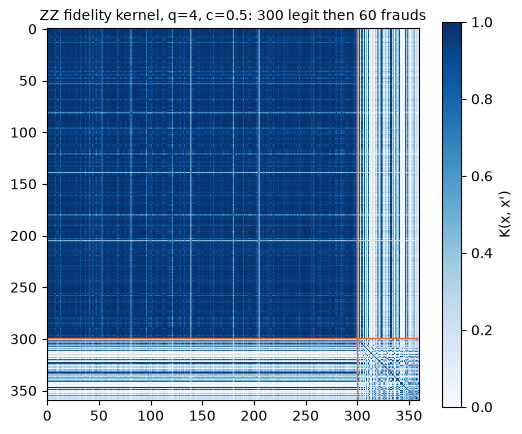

In [106]:
# - kernel heatmap, legit points first and frauds at the end
rng = np.random.default_rng(SETTINGS["seed"])
legit = rng.choice(np.where(y_train == 0)[0], ex["n_legit"], replace=False)
rows = np.r_[legit, rng.choice(np.where(y_train == 1)[0], ex["n_fraud"], replace=False)]
K_example = fidelity_kernel(A_train[rows], A_train[rows], ex["feature_map"], SETTINGS["reps"])

plt.figure(figsize=(6, 5))
plt.imshow(K_example, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="K(x, x')")
plt.axhline(ex["n_legit"] - 0.5, color=SETTINGS["colors"]["fraud"], linewidth=1)
plt.axvline(ex["n_legit"] - 0.5, color=SETTINGS["colors"]["fraud"], linewidth=1)
plt.title(f"{ex['feature_map'].upper()} fidelity kernel, q={ex['q']}, c={ex['c']}: "
          f"{ex['n_legit']} legit then {len(rows) - ex['n_legit']} frauds", fontsize=10)
plt.show()

## 6. Projected kernel

$K_P(x, x') = \exp\!\big(-\gamma \sum_k \lVert \rho_k(x) - \rho_k(x') \rVert_F^2\big)$, where $\rho_k$ is the reduced state of qubit $k$.
It compares small 2×2 states per qubit instead of the full $2^n$ state, so it shouldn't flatten out as fast when qubits are added (Huang et al. 2021). It can still flatten out if the single-qubit states get close to maximally mixed.

In [107]:
# - one-qubit reduced density matrices and the projected kernel
def one_qubit_rdms(state, n):
    psi = state.reshape([2] * n)
    rdms = []
    for k in range(n):
        M = np.moveaxis(psi, k, 0).reshape(2, -1)
        rdms.append(M @ M.conj().T)
    return np.array(rdms)


def rdm_features(X, feature_map, reps):
    n = X.shape[1]
    rdms = np.array([one_qubit_rdms(s, n) for s in feature_states(X, feature_map, reps)])
    flat = rdms.reshape(len(X), -1)
    return np.hstack([flat.real, flat.imag])


def projected_kernel(XA, XB, feature_map, reps, gamma):
    # Frobenius distance between RDMs = Euclidean distance between their entries,
    # so this is just an RBF kernel on features we can store classically
    return rbf_kernel(rdm_features(XA, feature_map, reps), rdm_features(XB, feature_map, reps), gamma)

In [108]:
# - check the RDMs against qiskit's partial_trace
n = ex["q"]
for x in A_train[:5]:
    state = feature_state(x, ex["feature_map"], SETTINGS["reps"])
    rdms = one_qubit_rdms(state, n)
    for k in range(n):
        reference = partial_trace(Statevector(state), [j for j in range(n) if j != n - 1 - k]).data
        assert np.allclose(rdms[k], reference)
        assert np.isclose(np.trace(rdms[k]), 1) and np.allclose(rdms[k], rdms[k].conj().T)
        assert np.linalg.eigvalsh(rdms[k]).min() > -1e-12

F = rdm_features(A_train[:1000], ex["feature_map"], SETTINGS["reps"])
K = projected_kernel(A_train[:1000], A_train[:1000], ex["feature_map"], SETTINGS["reps"], default_gamma(F))
assert np.allclose(K, K.T)
assert np.allclose(np.diag(K), 1)
assert np.linalg.eigvalsh(K).min() > -1e-8
print(f"projected kernel looks fine, smallest eigenvalue {np.linalg.eigvalsh(K).min():.1e}")

projected kernel looks fine, smallest eigenvalue -4.1e-13


The projected models are an SVM and a one-class SVM on an RBF of these RDM features, with γ tuned around a base value set by how much the features vary between points (section 3). They get run in section 8.

## 7. Kernel diagnostics

A fixed-γ study of how spread out each kernel is, how many directions it really uses, how close its states are to Haar-random, and how well it matches the labels. IQP-nn only appears here and in section 11. Projected kernels use the base γ here; the models in section 8 tune γ and save the same numbers for the kernel they actually used.

In [109]:
# - kernel diagnostics: concentration, effective rank, alignment, expressibility
def concentration(K):
    off_diagonal = K[~np.eye(len(K), dtype=bool)]
    return off_diagonal.mean(), off_diagonal.std()


def effective_rank(K):
    eigenvalues = np.clip(np.linalg.eigvalsh(K), 0, None)
    p = eigenvalues / eigenvalues.sum()
    p = p[p > 0]
    return np.exp(-(p * np.log(p)).sum())


def center(K):
    return K - K.mean(axis=0) - K.mean(axis=1)[:, None] + K.mean()


def alignment(K, y):
    s = 2 * y - 1
    Kc, Yc = center(K), center(np.outer(s, s))
    return (Kc * Yc).sum() / (np.linalg.norm(Kc) * np.linalg.norm(Yc))


def expressibility(K, n_qubits, bins=75):
    # KL divergence between the fidelities of pairs and those of Haar-random states,
    # P_Haar(F) = (N - 1)(1 - F)^(N - 2) with N = 2^q (Sim et al. 2019); 0 means Haar-like
    F = K[np.triu_indices(len(K), 1)]
    edges = np.linspace(0, 1, bins + 1)
    p = np.histogram(F, edges)[0] / len(F)
    N = 2**n_qubits
    haar = np.maximum((1 - edges[:-1]) ** (N - 1) - (1 - edges[1:]) ** (N - 1), 1e-300)
    keep = p > 0
    return (p[keep] * np.log(p[keep] / haar[keep])).sum()

In [110]:
# - test the diagnostics on toy kernels where the answer is known
N = 50
identity, ones = np.eye(N), np.ones((N, N))
y_toy = np.r_[np.zeros(40), np.ones(10)].astype(int)
s_toy = 2 * y_toy - 1
assert concentration(identity) == (0, 0)
assert np.isclose(effective_rank(identity), N) and np.isclose(effective_rank(ones), 1)
assert np.isclose(alignment(np.outer(s_toy, s_toy), y_toy), 1)
haar_states = np.random.default_rng(0).normal(size=(400, 4)) + 1j * np.random.default_rng(1).normal(size=(400, 4))
haar_states /= np.linalg.norm(haar_states, axis=1, keepdims=True)
assert expressibility(np.abs(haar_states.conj() @ haar_states.T) ** 2, 2) < 0.02
assert expressibility(np.ones((N, N)), 2) > 10
print("diagnostics give the right answers on toy kernels")

diagnostics give the right answers on toy kernels


In [111]:
# - compute the diagnostics for every q, map and bandwidth
def diagnose(K_train, y_train, sample, kernel, q):
    mean, std = concentration(K_train)
    return {"mean": mean, "std": std, "effective_rank": effective_rank(K_train[np.ix_(sample, sample)]),
            "alignment": alignment(K_train, y_train),
            "expressibility": expressibility(K_train, q) if kernel == "fidelity" else np.nan}


def diagnostics_current():
    if not os.path.exists(SETTINGS["diagnostics_file"]):
        return False
    d = pd.read_csv(SETTINGS["diagnostics_file"], dtype={"config": str})
    return ("expressibility" in d and set(d["feature_map"]) == set(SETTINGS["diag_feature_maps"])
            and (d["config"] == config_id()).all())


if SETTINGS["run_diagnostics"] or not diagnostics_current():
    rows = []
    for q in SETTINGS["diag_q_values"]:
        start = time.time()
        X_train, y_train, _, _ = load_prepared(SETTINGS["seed"])
        sample = np.sort(np.random.default_rng(SETTINGS["seed"]).choice(len(X_train), SETTINGS["diag_n"], replace=False))
        encoder = fit_encoder(X_train, q)
        for feature_map in SETTINGS["diag_feature_maps"]:
            for c in SETTINGS["bandwidths"]:
                A_train = encode(encoder, X_train, c)
                K_fidelity = fidelity_kernel(A_train, A_train, feature_map, SETTINGS["reps"])
                F = rdm_features(A_train, feature_map, SETTINGS["reps"])
                K_projected = rbf_kernel(F, F, default_gamma(F))
                for kernel, K in [("fidelity", K_fidelity), ("projected", K_projected)]:
                    rows.append({"config": config_id(), "feature_map": feature_map, "kernel": kernel, "q": q, "c": c,
                                 **diagnose(K, y_train, sample, kernel, q)})
        print(f"q={q}: {time.time() - start:.0f} s")
    os.makedirs(os.path.dirname(SETTINGS["diagnostics_file"]), exist_ok=True)
    pd.DataFrame(rows).to_csv(SETTINGS["diagnostics_file"], index=False)

diagnostics = pd.read_csv(SETTINGS["diagnostics_file"])

q=2: 21 s
q=4: 19 s
q=6: 24 s
q=8: 31 s
q=10: 55 s
q=12: 151 s


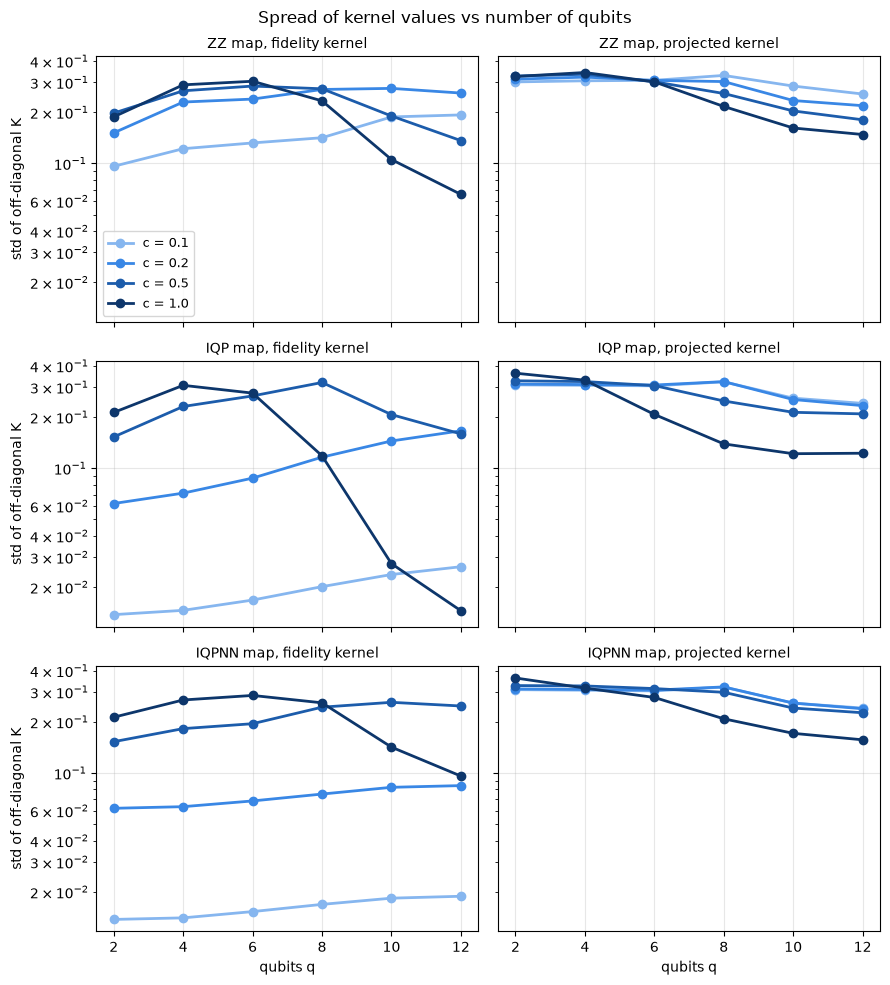

In [112]:
# - plot how the kernel spread changes with qubits
ramp = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']
fig, axes = plt.subplots(3, 2, figsize=(9, 10), sharex=True, sharey=True)
for row, feature_map in enumerate(SETTINGS["diag_feature_maps"]):
    for col, kernel in enumerate(["fidelity", "projected"]):
        ax = axes[row, col]
        for color, c in zip(ramp, SETTINGS["bandwidths"]):
            d = diagnostics[(diagnostics["feature_map"] == feature_map) & (diagnostics["kernel"] == kernel)
                            & (diagnostics["c"] == c)]
            ax.plot(d["q"], d["std"], marker="o", markersize=6, linewidth=2, color=color, label=f"c = {c}")
        ax.set_yscale("log")
        ax.set_title(f"{feature_map.upper()} map, {kernel} kernel", fontsize=10)
        ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("qubits q")
for ax in axes[:, 0]:
    ax.set_ylabel("std of off-diagonal K")
axes[0, 0].legend(fontsize=9)
fig.suptitle("Spread of kernel values vs number of qubits")
fig.tight_layout()
plt.show()

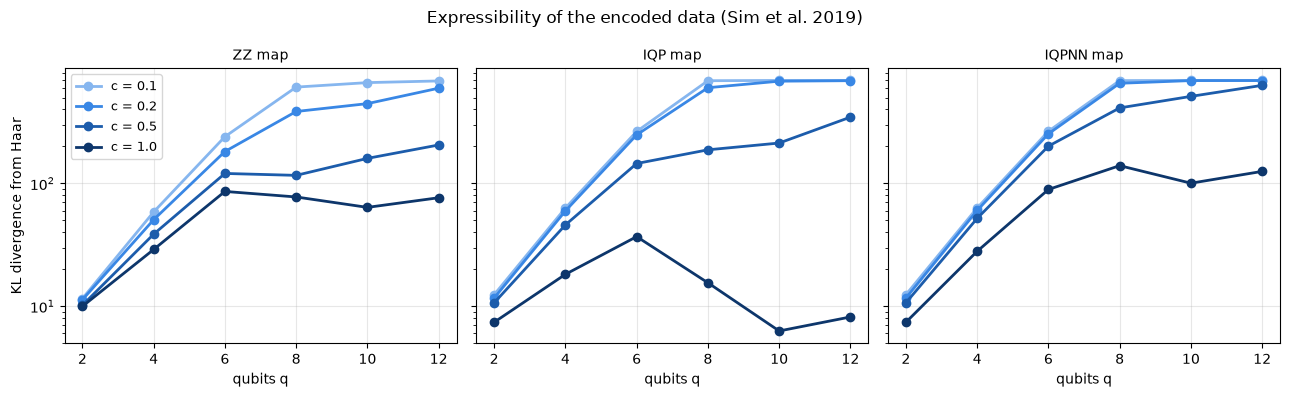

In [113]:
# - expressibility: how far the fidelities of data pairs are from those of Haar-random states (lower = closer)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, feature_map in zip(axes, SETTINGS["diag_feature_maps"]):
    for color, c in zip(ramp, SETTINGS["bandwidths"]):
        d = diagnostics[(diagnostics["feature_map"] == feature_map) & (diagnostics["kernel"] == "fidelity")
                        & (diagnostics["c"] == c)]
        ax.plot(d["q"], d["expressibility"], marker="o", markersize=6, linewidth=2, color=color, label=f"c = {c}")
    ax.set_yscale("log")
    ax.set_xlabel("qubits q")
    ax.set_title(f"{feature_map.upper()} map", fontsize=10)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("KL divergence from Haar")
axes[0].legend(fontsize=9)
fig.suptitle("Expressibility of the encoded data (Sim et al. 2019)")
fig.tight_layout()
plt.show()

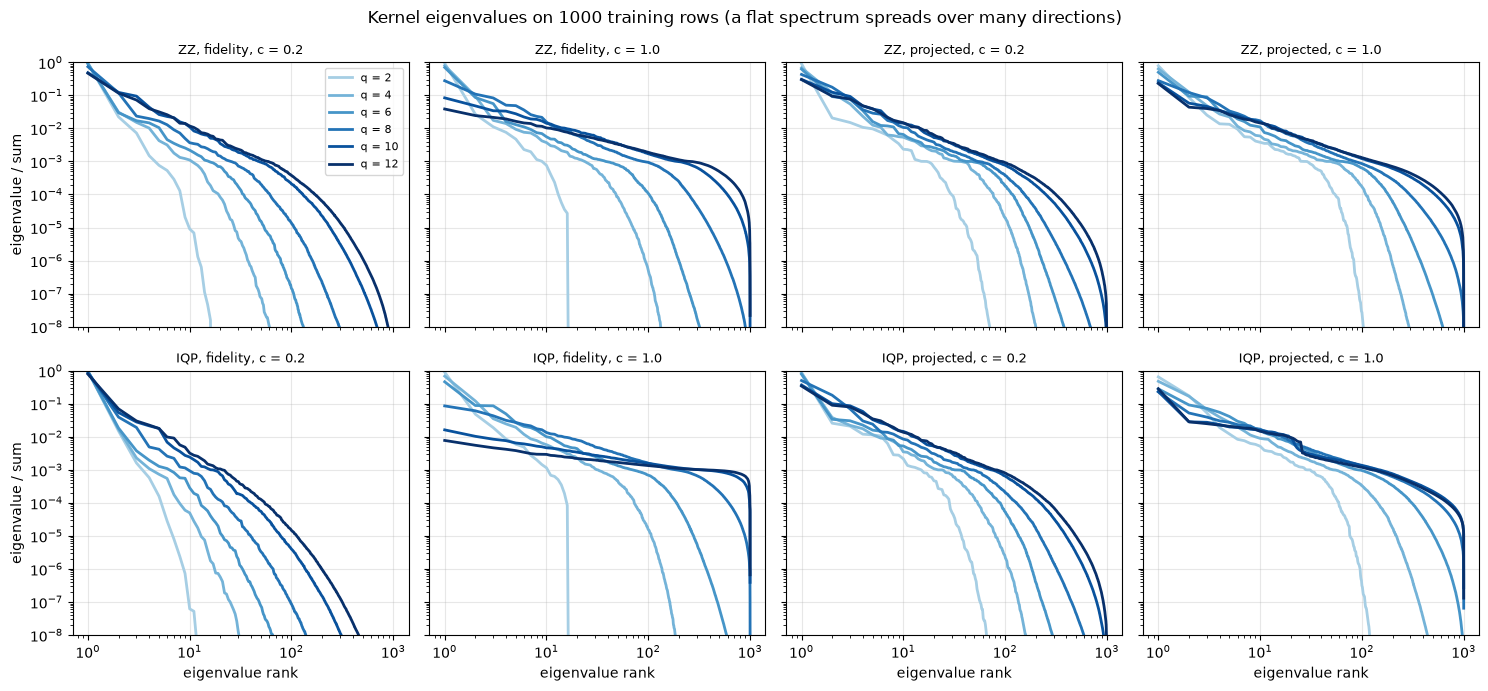

In [114]:
# - eigenvalue spectrum of each kernel on the diagnostics sample, one line per q
X_train, y_train, _, _ = load_prepared(SETTINGS["seed"])
sample = np.sort(np.random.default_rng(SETTINGS["seed"]).choice(len(X_train), SETTINGS["diag_n"], replace=False))
panels = [(m, kernel, c) for m in SETTINGS["feature_maps"] for kernel in ["fidelity", "projected"]
          for c in SETTINGS["spectrum_c"]]
q_colors = plt.cm.Blues(np.linspace(0.35, 1, len(SETTINGS["diag_q_values"])))

fig, axes = plt.subplots(len(SETTINGS["feature_maps"]), len(panels) // len(SETTINGS["feature_maps"]),
                         figsize=(15, 7), sharex=True, sharey=True)
for color, q in zip(q_colors, SETTINGS["diag_q_values"]):
    encoder = fit_encoder(X_train, q)
    for ax, (feature_map, kernel, c) in zip(axes.flat, panels):
        A = encode(encoder, X_train[sample], c)
        if kernel == "fidelity":
            K = fidelity_kernel(A, A, feature_map, SETTINGS["reps"])
        else:
            F = rdm_features(A, feature_map, SETTINGS["reps"])
            K = rbf_kernel(F, F, default_gamma(F))
        eigenvalues = np.sort(np.clip(np.linalg.eigvalsh(K), 0, None))[::-1]
        ax.plot(np.arange(1, len(K) + 1), eigenvalues / eigenvalues.sum(), linewidth=2, color=color, label=f"q = {q}")
for ax, (feature_map, kernel, c) in zip(axes.flat, panels):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylim(1e-8, 1)
    ax.set_title(f"{feature_map.upper()}, {kernel}, c = {c}", fontsize=9)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("eigenvalue rank")
for ax in axes[:, 0]:
    ax.set_ylabel("eigenvalue / sum")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Kernel eigenvalues on {SETTINGS['diag_n']} training rows (a flat spectrum spreads over many directions)")
fig.tight_layout()
plt.show()

## 8. Experiment

One loop over seed, q, bandwidth, feature map, kernel and classifier. Each CV fold refits the encoder on its own training rows before building the kernels. Runs already in the results file with the same config are skipped, so it can be stopped and restarted.

In [115]:
# - model names, which runs are done, and the states or RDM features for every CV fold plus the final fit
MODEL_NAMES = {("fidelity", "svm"): "qsvm", ("fidelity", "one_class"): "qocsvm",
               ("projected", "svm"): "pqsvm", ("projected", "one_class"): "pqocsvm"}


def done_runs():
    r = read_results()
    r = r[r["config"] == config_id()]
    return set(zip(r["model"], r["q"], r["seed"], r["c"].astype(float).round(6)))


def fit_and_transform(X_fit, X_eval, q, c):
    encoder = fit_encoder(X_fit, q)
    return encode(encoder, X_fit, c), encode(encoder, X_eval, c)


def kernel_inputs(kernel, feature_map, X_train, y_train, X_test, q, c):
    folds = []
    for tr, va in make_folds(y_train):
        A_fit, A_eval = fit_and_transform(X_train[tr], X_train[va], q, c)
        folds.append((tr, va, kernel_input(kernel, feature_map, A_fit), kernel_input(kernel, feature_map, A_eval)))
    A_train, A_test = fit_and_transform(X_train, X_test, q, c)
    # test rows stay as angles, run_models turns them into states one chunk at a time
    return folds, (kernel_input(kernel, feature_map, A_train), A_test)

In [116]:
# - the main sweep plus the extra q values, skips anything already in quantum_kernel_svm.csv
sweep_plan = [(s, q) for part in [SETTINGS["sweep"], SETTINGS["extra_q"]]
              for s in seeds[:part["n_seeds"]] for q in part["q_values"]]
kernels, classifiers = ["fidelity", "projected"], ["svm", "one_class"]
total = len(sweep_plan) * len(SETTINGS["bandwidths"]) * len(SETTINGS["feature_maps"]) * 4

if SETTINGS["RUN_SWEEP"]:
    done = done_runs()
    count, skipped, sweep_start = 0, 0, time.time()
    for s, q in sweep_plan:
        X_train, y_train, X_test, y_test = load_prepared(s)
        for c in SETTINGS["bandwidths"]:
            for feature_map in SETTINGS["feature_maps"]:
                for kernel in kernels:
                    todo = []
                    for clf in classifiers:
                        model = f"{MODEL_NAMES[(kernel, clf)]}_{feature_map}"
                        if (model, str(q), str(s), round(c, 6)) in done:
                            count, skipped = count + 1, skipped + 1
                        else:
                            todo.append(clf)
                    if not todo:
                        continue
                    start = time.time()
                    folds, final = kernel_inputs(kernel, feature_map, X_train, y_train, X_test, q, c)
                    kernel_seconds = time.time() - start
                    start = time.time()
                    outputs = run_models(kernel, feature_map, todo, folds, final, y_train)
                    fit_seconds = (time.time() - start) / len(todo)
                    folds = final = None
                    for clf, (scores, params) in outputs.items():
                        count += 1
                        params.update(reps=SETTINGS["reps"], fit_seconds=round(fit_seconds, 1),
                                      kernel_seconds=round(kernel_seconds, 1))
                        metrics = evaluate(y_test, scores)
                        save_result(f"{MODEL_NAMES[(kernel, clf)]}_{feature_map}", q, s, params, metrics,
                                    len(y_train), len(y_test), c=c)
                        print(f"[{count}/{total}] seed {s} q={q} c={c} {feature_map} {kernel} {clf}: "
                              f"PR-AUC {metrics['pr_auc']:.3f} ({params['fit_seconds'] + kernel_seconds:.1f} s)")
    print(f"finished: {count - skipped} new runs, {skipped} already done, {time.time() - sweep_start:.0f} s")

finished: 0 new runs, 96 already done, 0 s


In [117]:
# - list the runs and guess how long the full grid takes
results = read_results()
swept = results[results["config"] == config_id()].copy()
params = swept["params"].map(json.loads)
# both classifiers share one kernel, so each run gets half its cost
swept["seconds"] = params.map(lambda p: p["fit_seconds"] + p.get("kernel_seconds", 0) / 2)
swept["kernel"] = np.where(swept["model"].str.startswith("pq"), "projected", "fidelity")
swept["q"] = swept["q"].astype(int)

columns = ["model", "q", "seed", "c", "pr_auc", "roc_auc", "recall_fpr1", "recall_fpr5", "seconds"]
print(swept[columns].sort_values(["q", "c", "model"]).round(3).to_string(index=False))

seconds = swept.groupby(["kernel", "q"])["seconds"].mean()
runs_per_seed = len(SETTINGS["bandwidths"]) * len(SETTINGS["feature_maps"]) * 2
grid = [(SETTINGS["n_repeats"], q) for q in SETTINGS["q_values"]]
grid += [(SETTINGS["extra_q"]["n_seeds"], q) for q in SETTINGS["extra_q"]["q_values"]]
estimate = 0
for kernel in kernels:
    measured = seconds[kernel]
    if len(measured) >= 2:
        # fit seconds = a * b**q to guess the q values we haven't timed
        slope, intercept = np.polyfit(measured.index, np.log(measured.values), 1)
        per_run = {q: measured.get(q, np.exp(intercept + slope * q)) for _, q in grid}
    else:
        per_run = {q: measured.mean() for _, q in grid}
    estimate += sum(n_seeds * runs_per_seed * per_run[q] for n_seeds, q in grid)
full_total = 2 * runs_per_seed * sum(n_seeds for n_seeds, _ in grid)
print(f"\nfull grid plus the extra q values is {full_total} runs, roughly {estimate / 60:.0f} min "
      "(the guess for big q is rough)")

      model  q seed   c  pr_auc  roc_auc  recall_fpr1  recall_fpr5  seconds
pqocsvm_iqp  2   42 0.1   0.657    0.853        0.768        0.779     5.75
 pqocsvm_zz  2   42 0.1   0.565    0.895        0.779        0.811     6.00
  pqsvm_iqp  2   42 0.1   0.675    0.928        0.768        0.811     5.75
   pqsvm_zz  2   42 0.1   0.633    0.890        0.768        0.811     6.00
 qocsvm_iqp  2   42 0.1   0.559    0.886        0.768        0.779     2.85
  qocsvm_zz  2   42 0.1   0.511    0.915        0.768        0.800     3.70
   qsvm_iqp  2   42 0.1   0.671    0.925        0.768        0.800     2.85
    qsvm_zz  2   42 0.1   0.558    0.910        0.768        0.811     3.70
pqocsvm_iqp  2   42 0.2   0.660    0.851        0.768        0.779     6.05
 pqocsvm_zz  2   42 0.2   0.649    0.847        0.768        0.779     5.85
  pqsvm_iqp  2   42 0.2   0.701    0.929        0.779        0.811     6.05
   pqsvm_zz  2   42 0.2   0.490    0.919        0.768        0.811     5.85
 qocsvm_iqp 

In [118]:
# - quantum PR-AUC table
stats = swept.groupby(["model", "c", "q"])["pr_auc"].agg(["mean", "std", "count"])
pr_table = (stats["mean"].map("{:.3f}".format) + " ± " + stats["std"].fillna(0).map("{:.3f}".format)).unstack("q")
print(f"test PR-AUC for each model and c, averaged over up to {stats['count'].max()} seeds (± is the std)")
print(pr_table.to_string())

test PR-AUC for each model and c, averaged over up to 1 seeds (± is the std)
q                           2              4              10
model       c                                               
pqocsvm_iqp 0.1  0.657 ± 0.000  0.645 ± 0.000  0.460 ± 0.000
            0.2  0.660 ± 0.000  0.667 ± 0.000  0.494 ± 0.000
            0.5  0.626 ± 0.000  0.489 ± 0.000  0.239 ± 0.000
            1.0  0.552 ± 0.000  0.197 ± 0.000  0.008 ± 0.000
pqocsvm_zz  0.1  0.565 ± 0.000  0.621 ± 0.000  0.343 ± 0.000
            0.2  0.649 ± 0.000  0.541 ± 0.000  0.314 ± 0.000
            0.5  0.651 ± 0.000  0.580 ± 0.000  0.178 ± 0.000
            1.0  0.678 ± 0.000  0.574 ± 0.000  0.250 ± 0.000
pqsvm_iqp   0.1  0.675 ± 0.000  0.698 ± 0.000  0.639 ± 0.000
            0.2  0.701 ± 0.000  0.728 ± 0.000  0.686 ± 0.000
            0.5  0.615 ± 0.000  0.708 ± 0.000  0.387 ± 0.000
            1.0  0.647 ± 0.000  0.167 ± 0.000  0.032 ± 0.000
pqsvm_zz    0.1  0.633 ± 0.000  0.659 ± 0.000  0.515 ± 0.000
        

## 9. Results

This section only reads the saved results. Where a bandwidth c has to be chosen, it's chosen per seed from the training CV score, not the test score. Every seed has the same frauds and the same test set and only the sampled legit rows change, so the error bars show that variation only.

In [119]:
# - load quantum_kernel_svm.csv and pick c per seed using the CV score
results = read_results()
results = results[results["config"] == config_id()].copy()
results["c"] = results["c"].astype(float)
results["q"] = pd.to_numeric(results["q"], errors="coerce")
params = results["params"].map(json.loads)
for key in ["cv_pr_auc", "kernel_mean", "kernel_std", "kernel_alignment"]:
    results[key] = params.map(lambda p: p.get(key, np.nan))

quantum = results[results["c"].notna()].copy()
quantum["kernel"] = np.where(quantum["model"].str.startswith("pq"), "projected", "fidelity")
quantum["feature_map"] = quantum["model"].str.split("_").str[-1]
quantum["classifier"] = np.where(quantum["model"].str.contains("ocsvm"), "one_class", "svm")

quantum_cv = quantum.sort_values(["cv_pr_auc", "c"], ascending=[False, True]).drop_duplicates(["model", "q", "seed"])
svm_cv = quantum_cv[quantum_cv["classifier"] == "svm"]

fraud_rate = load_prepared(SETTINGS["seed"])[3].mean()
map_colors = {"zz": "#2a78d6", "iqp": "#8a4fd6", "iqpnn": "#1f9e74"}
print(f"loaded {len(quantum)} runs, fraud rate in test is {fraud_rate:.4f}")

loaded 96 runs, fraud rate in test is 0.0017


In [120]:
# - fixed-gamma diagnostics from section 7 next to test PR-AUC
pr = quantum[quantum["classifier"] == "svm"].groupby(["model", "q", "c"])["pr_auc"].mean()
table = diagnostics[diagnostics["q"].isin(SETTINGS["q_values"] + SETTINGS["extra_q"]["q_values"])
                    & diagnostics["feature_map"].isin(SETTINGS["feature_maps"])].copy()
model_name = np.where(table["kernel"] == "fidelity", "qsvm_", "pqsvm_") + table["feature_map"]
table["pr_auc"] = [pr.get((m, q, c), np.nan) for m, q, c in zip(model_name, table["q"], table["c"])]
table = table.set_index(["feature_map", "kernel", "q", "c"]).sort_index()
print(f"diagnostics from the seed {SETTINGS['seed']} training sample (effective rank uses {SETTINGS['diag_n']} rows), "
      "pr_auc is the test mean over seeds")
print(table.round(3).to_string())

diagnostics from the seed 42 training sample (effective rank uses 1000 rows), pr_auc is the test mean over seeds
                                config   mean    std  effective_rank  alignment  expressibility  pr_auc
feature_map kernel    q  c                                                                             
iqp         fidelity  2  0.1  944be19e  0.997  0.014           1.027      0.597          12.418   0.671
                         0.2  944be19e  0.983  0.062           1.102      0.633          11.659   0.599
                         0.5  944be19e  0.945  0.153           1.281      0.618          10.663   0.619
                         1.0  944be19e  0.883  0.213           1.611      0.473           7.406   0.328
                      4  0.1  944be19e  0.996  0.015           1.032      0.604          63.066   0.684
                         0.2  944be19e  0.978  0.071           1.134      0.652          59.744   0.613
                         0.5  944be19e  0.890  0.231   

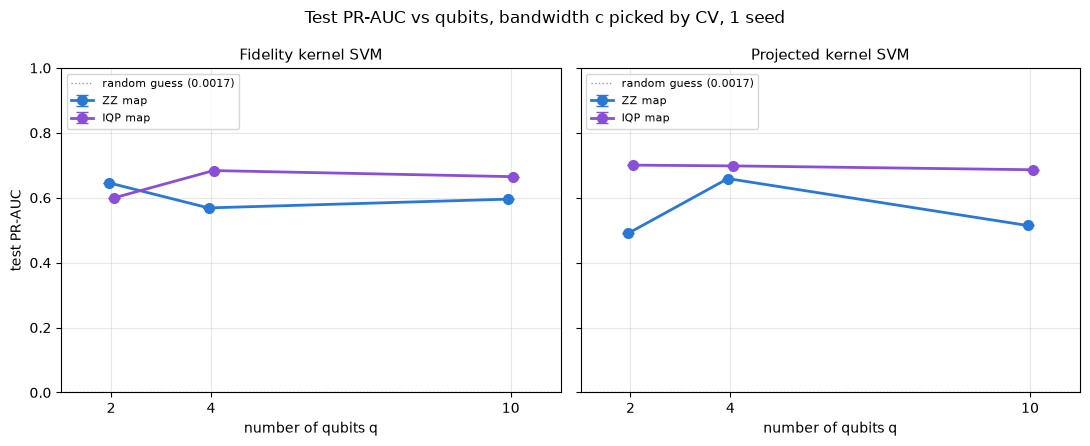

In [121]:
# - PR-AUC vs qubits for each kernel and feature map
q_seen = sorted(svm_cv["q"].astype(int).unique())
n_seeds = svm_cv["seed"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, kernel in zip(axes, ["fidelity", "projected"]):
    for i, m in enumerate(SETTINGS["feature_maps"]):
        d = svm_cv[(svm_cv["kernel"] == kernel) & (svm_cv["feature_map"] == m)]
        stats = d.groupby("q")["pr_auc"].agg(["mean", "std"])
        ax.errorbar(stats.index + 0.1 * (i - 0.5), stats["mean"], yerr=stats["std"].fillna(0), label=f"{m.upper()} map",
                    color=map_colors[m], marker="o", markersize=7, linewidth=2, capsize=4)
    ax.axhline(fraud_rate, color="#999999", linestyle=":", linewidth=1, label=f"random guess ({fraud_rate:.4f})")
    ax.set_title(f"{kernel.capitalize()} kernel SVM", fontsize=11)
    ax.set_xlabel("number of qubits q")
    ax.set_xticks(q_seen)
    ax.set_xlim(min(q_seen) - 1, max(q_seen) + 1)
    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("test PR-AUC" + (" (mean ± std across legit samples)" if n_seeds > 1 else ""))
fig.suptitle(f"Test PR-AUC vs qubits, bandwidth c picked by CV, {n_seeds} seed{'s' if n_seeds > 1 else ''}", fontsize=12)
fig.tight_layout()
plt.show()

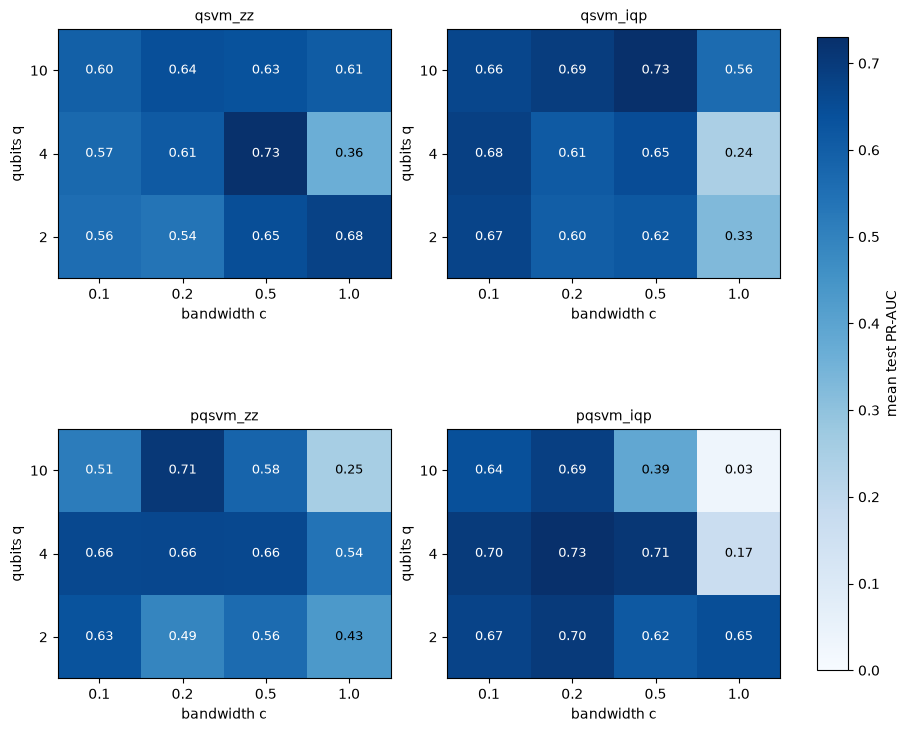

In [122]:
# - PR-AUC heatmaps over q and c
svm_rows = quantum[quantum["classifier"] == "svm"]
grids = {m: svm_rows[svm_rows["model"] == m].groupby(["q", "c"])["pr_auc"].mean().unstack("c")
         for m in ["qsvm_zz", "qsvm_iqp", "pqsvm_zz", "pqsvm_iqp"]}
vmax = max(g.values.max() for g in grids.values())

fig, axes = plt.subplots(2, 2, figsize=(9, 8), layout="constrained")
for ax, (model, grid) in zip(axes.flat, grids.items()):
    image = ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=vmax, origin="lower")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            value = grid.values[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if value > 0.6 * vmax else "black")
    ax.set_xticks(range(grid.shape[1]), grid.columns)
    ax.set_yticks(range(grid.shape[0]), grid.index.astype(int))
    ax.set_xlabel("bandwidth c")
    ax.set_ylabel("qubits q")
    ax.set_title(model, fontsize=10)
fig.colorbar(image, ax=axes, label="mean test PR-AUC", shrink=0.8)
plt.show()

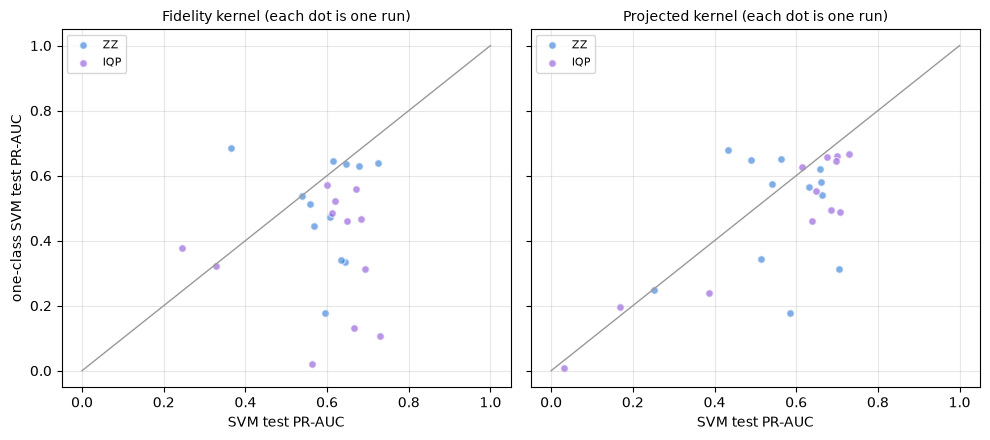

fraction of runs where the SVM beats the one-class SVM: {'fidelity': 0.83, 'projected': 0.75}
classifier    svm  one_class
kernel                      
fidelity    0.593      0.433
projected   0.558      0.485


In [123]:
# - SVM vs one-class SVM, run by run
svm_vs_oc = quantum.pivot_table(index=["kernel", "feature_map", "q", "seed", "c"], columns="classifier",
                            values="pr_auc").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, kernel in zip(axes, ["fidelity", "projected"]):
    for m in SETTINGS["feature_maps"]:
        d = svm_vs_oc[(svm_vs_oc["kernel"] == kernel) & (svm_vs_oc["feature_map"] == m)]
        ax.scatter(d["svm"], d["one_class"], s=30, alpha=0.6, color=map_colors[m], edgecolor="white",
                   linewidth=1, label=m.upper())
    ax.plot([0, 1], [0, 1], color="#999999", linewidth=1)
    ax.set_title(f"{kernel.capitalize()} kernel (each dot is one run)", fontsize=10)
    ax.set_xlabel("SVM test PR-AUC")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("one-class SVM test PR-AUC")
fig.tight_layout()
plt.show()

wins = (svm_vs_oc["svm"] > svm_vs_oc["one_class"]).groupby(svm_vs_oc["kernel"]).mean()
print("fraction of runs where the SVM beats the one-class SVM:", wins.round(2).to_dict())
print(svm_vs_oc.groupby("kernel")[["svm", "one_class"]].mean().round(3))

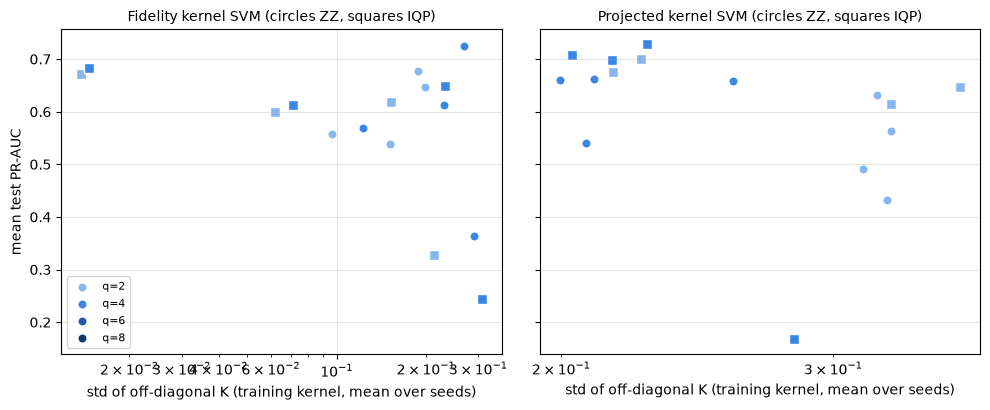

fidelity kernel, spearman corr with PR-AUC:  std -0.12  mean 0.13  alignment 0.19
projected kernel, spearman corr with PR-AUC:  std 0.05  mean 0.73  alignment 0.56


In [124]:
# - does kernel spread explain PR-AUC? uses the kernel each model actually trained on
per_config = svm_rows.groupby(["kernel", "feature_map", "q", "c"])[["kernel_std", "kernel_mean", "kernel_alignment",
                                                                    "pr_auc"]].mean().reset_index()

q_colors = dict(zip(SETTINGS["q_values"], ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, kernel in zip(axes, ["fidelity", "projected"]):
    for q in SETTINGS["q_values"]:
        for m, marker in [("zz", "o"), ("iqp", "s")]:
            d = per_config[(per_config["kernel"] == kernel) & (per_config["q"] == q) & (per_config["feature_map"] == m)]
            ax.scatter(d["kernel_std"], d["pr_auc"], s=45, marker=marker, color=q_colors[q], edgecolor="white",
                       linewidth=1, label=f"q={q}" if m == "zz" else None)
    ax.set_xscale("log")
    ax.set_xlabel("std of off-diagonal K (training kernel, mean over seeds)")
    ax.set_title(f"{kernel.capitalize()} kernel SVM (circles ZZ, squares IQP)", fontsize=10)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mean test PR-AUC")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

for kernel in ["fidelity", "projected"]:
    d = per_config[per_config["kernel"] == kernel]
    print(f"{kernel} kernel, spearman corr with PR-AUC:  std {d['kernel_std'].corr(d['pr_auc'], method='spearman'):.2f}  "
          f"mean {d['kernel_mean'].corr(d['pr_auc'], method='spearman'):.2f}  "
          f"alignment {d['kernel_alignment'].corr(d['pr_auc'], method='spearman'):.2f}")

In [125]:
# - Wilcoxon test: best fidelity model vs best projected model
cv_means = svm_cv.groupby(["kernel", "model", "q"])["cv_pr_auc"].mean()
best = {kernel: cv_means[kernel].idxmax() for kernel in ["fidelity", "projected"]}
for kernel, (model, q) in best.items():
    print(f"best {kernel} model on CV: {model} with q={int(q)}")


def best_runs(kernel):
    model, q = best[kernel]
    return svm_cv[(svm_cv["model"] == model) & (svm_cv["q"] == q)].set_index("seed")


paired = pd.DataFrame({"c_fidelity": best_runs("fidelity")["c"], "fidelity": best_runs("fidelity")["pr_auc"],
                       "c_projected": best_runs("projected")["c"], "projected": best_runs("projected")["pr_auc"]})
paired["difference"] = paired["projected"] - paired["fidelity"]
print(paired.round(3))
test = wilcoxon(paired["projected"], paired["fidelity"])
print(f"wilcoxon over {len(paired)} seeds: median diff (projected - fidelity) {paired['difference'].median():+.3f}, "
      f"p = {test.pvalue:.3f} (with only 5 pairs p can't go below 0.0625)")

best fidelity model on CV: qsvm_iqp with q=10
best projected model on CV: pqsvm_iqp with q=10
      c_fidelity  fidelity  c_projected  projected  difference
seed                                                          
42           0.1     0.665          0.2      0.686       0.021
wilcoxon over 1 seeds: median diff (projected - fidelity) +0.021, p = 1.000 (with only 5 pairs p can't go below 0.0625)


### Findings

To be rewritten once the v3 sweep (all training frauds, full test split, preprocessing inside CV, γ from feature spread, batched test scoring) has run. The earlier results are kept in `results/quantum_kernel_svm/quantum_kernel_svm_v1.csv`; their projected-kernel numbers used a badly scaled γ and should not be quoted.

Limits that hold either way:
- Changing q changes both the number of qubits and how many PCA features the model sees, so the two effects are mixed.
- ZZ and IQP differ in their phase function as well as their connections; IQP-nn separates the two only in the diagnostics and circuit costs.
- The extra PCA compresses features that are already PCA outputs.
- Error bars show variation across the sampled legit training rows only; the frauds and the test set are the same for every seed.
- The one-class models are fitted on legit rows only but tuned with fraud labels, so they aren't fully unsupervised.
- Everything outside section 11 is a noiseless simulation with exact kernel values, and there is no classical baseline in this notebook.

## 10. Best models up close

The CV-best fidelity and projected SVMs are refitted on one seed, so we can look at the score of every test transaction. The thresholds below are picked on the test labels, so they describe the models; a real alert threshold would be fixed on training data first.

In [126]:
# - refit the CV-best fidelity and projected SVMs on one seed
close_up = {}
for kernel, (model, q) in best.items():
    row = svm_cv[(svm_cv["model"] == model) & (svm_cv["q"] == q) & (svm_cv["seed"] == str(SETTINGS["seed"]))].iloc[0]
    feature_map, q = model.split("_")[-1], int(q)
    X_train, y_train, X_test, y_test = load_prepared(SETTINGS["seed"])
    folds, final = kernel_inputs(kernel, feature_map, X_train, y_train, X_test, q, row["c"])
    scores, params = run_models(kernel, feature_map, ["svm"], folds, final, y_train)["svm"]
    assert np.isclose(average_precision_score(y_test, scores), row["pr_auc"]), "refit doesn't match the saved run"
    A_test = encode(fit_encoder(X_train, q), X_test, row["c"])
    close_up[kernel] = {"model": model, "feature_map": feature_map, "y": y_test, "scores": scores,
                        "A_test": A_test, "params": params}
    print(f"{kernel}: {model}, q={q}, c={row['c']}, test PR-AUC {row['pr_auc']:.3f}")

kernel_colors = {"fidelity": "#2a78d6", "projected": "#8a4fd6"}

fidelity: qsvm_iqp, q=10, c=0.1, test PR-AUC 0.665
projected: pqsvm_iqp, q=10, c=0.2, test PR-AUC 0.686


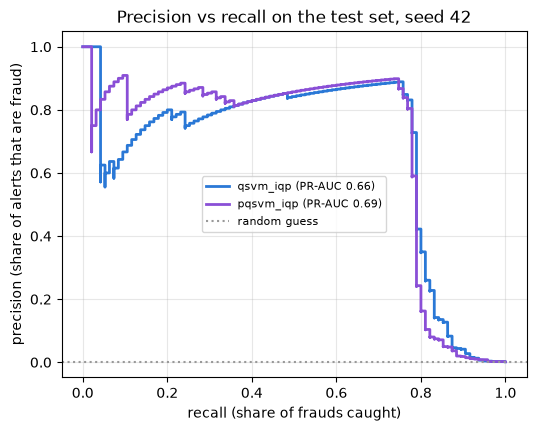

In [127]:
# - precision-recall curves, the dotted line is what random guessing gets
plt.figure(figsize=(6, 4.5))
for kernel, r in close_up.items():
    precision, recall, _ = precision_recall_curve(r["y"], r["scores"])
    plt.step(recall, precision, where="post", linewidth=2, color=kernel_colors[kernel],
             label=f"{r['model']} (PR-AUC {average_precision_score(r['y'], r['scores']):.2f})")
plt.axhline(fraud_rate, color="#999999", linestyle=":", label="random guess")
plt.xlabel("recall (share of frauds caught)")
plt.ylabel("precision (share of alerts that are fraud)")
plt.title(f"Precision vs recall on the test set, seed {SETTINGS['seed']}")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.show()

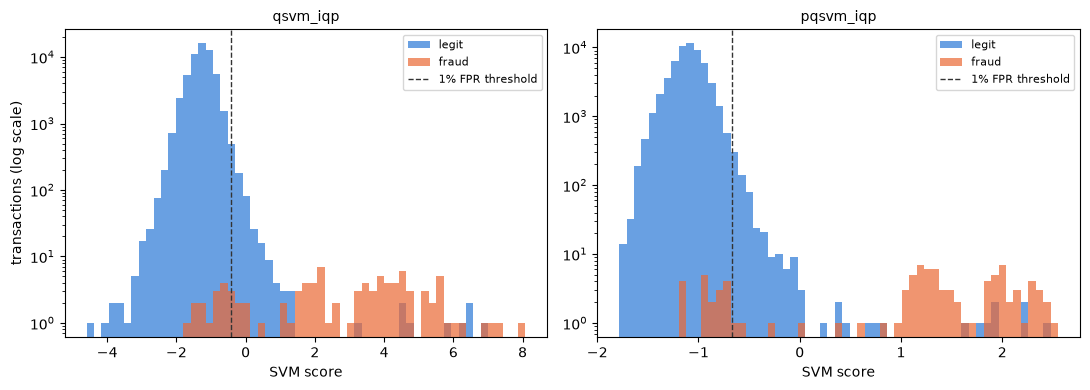

In [128]:
# - where the frauds land among the scores, dashed line = threshold that flags 1% of legit (picked on test)
def threshold_at_fpr(y, scores, max_fpr):
    fpr, _, thresholds = roc_curve(y, scores)
    return thresholds[np.where(fpr <= max_fpr)[0][-1]]


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (kernel, r) in zip(axes, close_up.items()):
    r["threshold"] = threshold_at_fpr(r["y"], r["scores"], 0.01)
    bins = np.linspace(r["scores"].min(), r["scores"].max(), 60)
    for label, cls in [("legit", 0), ("fraud", 1)]:
        ax.hist(r["scores"][r["y"] == cls], bins=bins, color=SETTINGS["colors"][label], alpha=0.7, label=label)
    ax.axvline(r["threshold"], color="#333333", linestyle="--", linewidth=1, label="1% FPR threshold")
    ax.set_yscale("log")
    ax.set_xlabel("SVM score")
    ax.set_title(r["model"], fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylabel("transactions (log scale)")
fig.tight_layout()
plt.show()

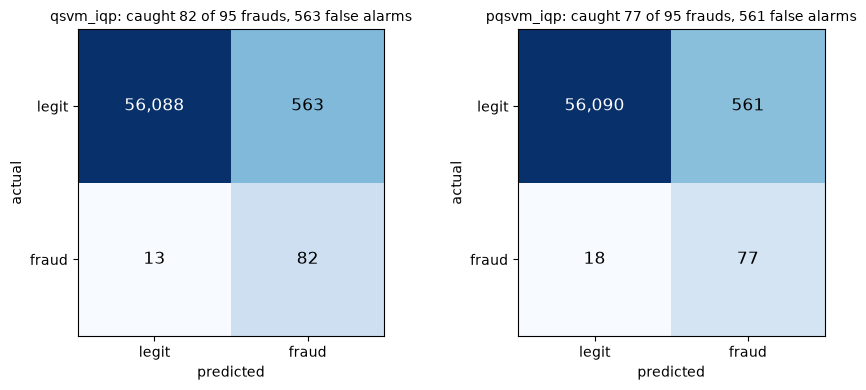

In [129]:
# - confusion matrix at that threshold
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (kernel, r) in zip(axes, close_up.items()):
    cm = confusion_matrix(r["y"], r["scores"] >= r["threshold"])
    ax.imshow(np.log10(cm + 1), cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > 1000 else "black")
    ax.set_xticks([0, 1], ["legit", "fraud"])
    ax.set_yticks([0, 1], ["legit", "fraud"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(f"{r['model']}: caught {cm[1, 1]} of {cm[1].sum()} frauds, {cm[0, 1]} false alarms", fontsize=10)
fig.tight_layout()
plt.show()

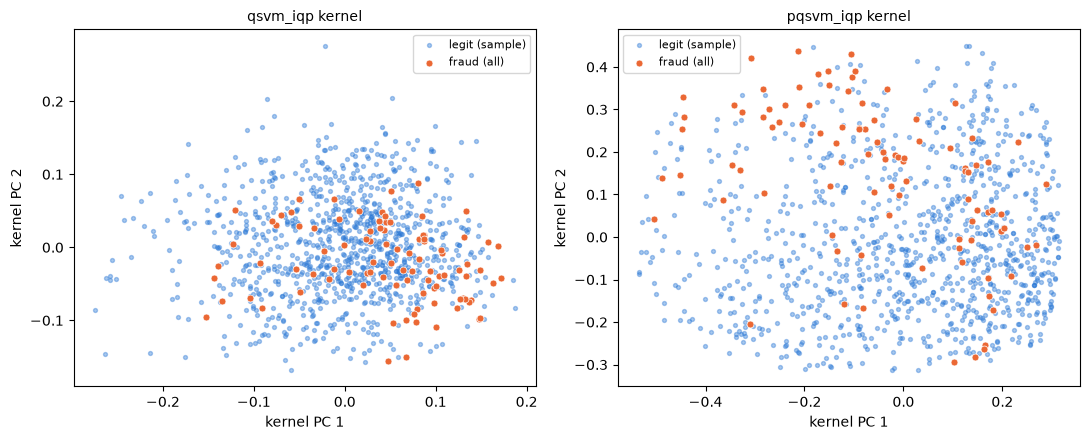

In [130]:
# - kernel PCA: the test set as each quantum kernel sees it (all frauds plus 1000 legit)
def kernel_pca(K, n_components=2):
    values, vectors = np.linalg.eigh(center(K))
    top = np.argsort(values)[::-1][:n_components]
    return vectors[:, top] * np.sqrt(np.clip(values[top], 0, None))


rng = np.random.default_rng(SETTINGS["seed"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (kernel, r) in zip(axes, close_up.items()):
    rows = np.r_[rng.choice(np.where(r["y"] == 0)[0], 1000, replace=False), np.where(r["y"] == 1)[0]]
    A = r["A_test"][rows]
    if kernel == "fidelity":
        K = fidelity_kernel(A, A, r["feature_map"], SETTINGS["reps"])
    else:
        F = rdm_features(A, r["feature_map"], SETTINGS["reps"])
        K = rbf_kernel(F, F, r["params"]["gamma"])
    coords = kernel_pca(K)
    fraud_mask = r["y"][rows] == 1
    ax.scatter(*coords[~fraud_mask].T, s=8, alpha=0.4, color=SETTINGS["colors"]["legit"], label="legit (sample)")
    ax.scatter(*coords[fraud_mask].T, s=25, color=SETTINGS["colors"]["fraud"], edgecolor="white", linewidth=0.5,
               label="fraud (all)")
    ax.set_xlabel("kernel PC 1")
    ax.set_ylabel("kernel PC 2")
    ax.set_title(f"{r['model']} kernel", fontsize=10)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Actual vs detected fraud

How many of the real frauds in the test set the best models catch on every seed, when they're allowed to flag 1% or 5% of legit transactions.

frauds in the test set vs frauds caught when flagging 1% or 5% of legit transactions
      actual  fidelity 1%  fidelity 5%  projected 1%  projected 5%
seed                                                              
42        95           82           86            77            84

average over seeds
actual          95.0
fidelity 1%     82.0
fidelity 5%     86.0
projected 1%    77.0
projected 5%    84.0


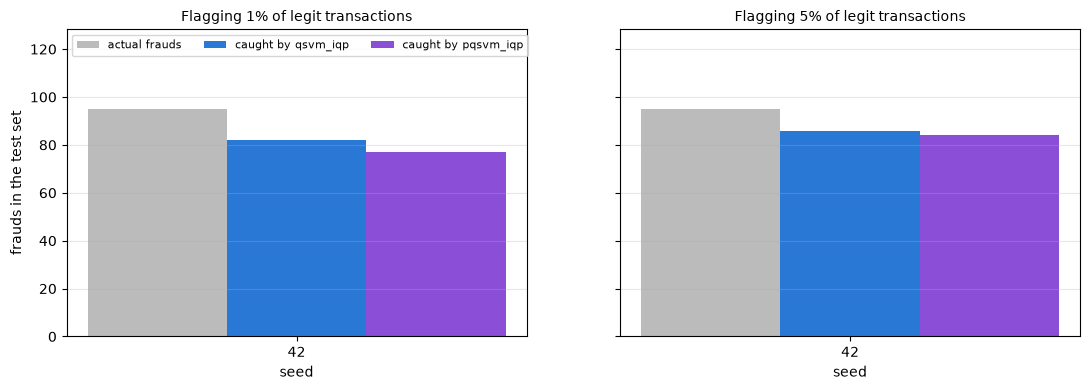

In [131]:
# - actual frauds vs frauds caught by the best models, every seed
n_frauds = int(load_prepared(SETTINGS["seed"])[3].sum())
detected = pd.DataFrame({"actual": n_frauds}, index=sorted(svm_cv["seed"].unique()))
detected.index.name = "seed"
for kernel, (model, q) in best.items():
    runs = svm_cv[(svm_cv["model"] == model) & (svm_cv["q"] == q)].set_index("seed")
    for fpr in [1, 5]:
        detected[f"{kernel} {fpr}%"] = (runs[f"recall_fpr{fpr}"] * n_frauds).round().astype(int)
print("frauds in the test set vs frauds caught when flagging 1% or 5% of legit transactions")
print(detected.to_string())
print("\naverage over seeds")
print(detected.mean().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
x = np.arange(len(detected))
for ax, fpr in zip(axes, [1, 5]):
    ax.bar(x - 0.27, detected["actual"], width=0.27, color="#bbbbbb", label="actual frauds")
    for shift, kernel in [(0, "fidelity"), (0.27, "projected")]:
        ax.bar(x + shift, detected[f"{kernel} {fpr}%"], width=0.27, color=kernel_colors[kernel],
               label=f"caught by {best[kernel][0]}")
    ax.set_xticks(x, detected.index)
    ax.set_xlabel("seed")
    ax.set_title(f"Flagging {fpr}% of legit transactions", fontsize=10)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("frauds in the test set")
axes[0].set_ylim(0, n_frauds * 1.35)
axes[0].legend(fontsize=8, ncols=3, loc="upper left")
fig.tight_layout()
plt.show()

## 11. Can it run on a quantum computer?

Everything above uses exact kernel values. Here: what the circuits cost on an IBM device, how many shots the kernels need, and what a noisy fake IBM backend does to them.

compute-uncompute circuit, reps=2, transpiled for fake_torino
            depth            two_qubit_gates           two_qubit_depth          
feature_map   iqp iqpnn   zz             iqp iqpnn  zz             iqp iqpnn  zz
q                                                                               
2              20    20   20               3     3   3               3     3   3
4             221    75   77              82    22  22              68    18  18
6             429   110  105             207    38  38             142    26  26
8             722   137  134             430    54  54             248    34  34
10            949   164  166             685    70  70             325    42  42
12            994   191  188             902    86  86             332    50  50


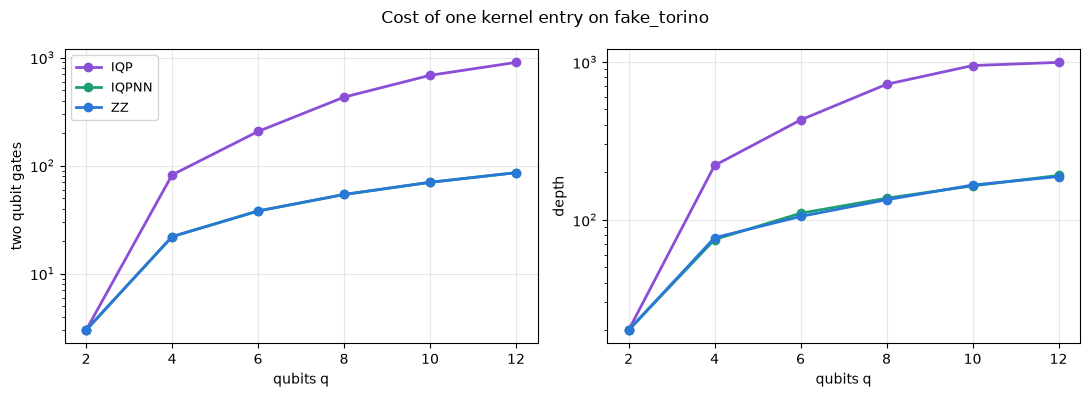

In [132]:
# - circuit cost on a fake IBM backend: transpile one compute-uncompute circuit per map and q
backend = getattr(fake_provider, SETTINGS["backend"])()
pass_manager = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=SETTINGS["seed"])


def kernel_circuit(x, x_prime, feature_map):
    qc = feature_circuit(x, feature_map, SETTINGS["reps"])
    qc.compose(feature_circuit(x_prime, feature_map, SETTINGS["reps"]).inverse(), inplace=True)
    qc.measure_all()
    return qc


def is_two_qubit(instruction):
    return instruction.operation.num_qubits == 2 and instruction.operation.name != "barrier"


rng = np.random.default_rng(SETTINGS["seed"])
rows = []
for q in SETTINGS["diag_q_values"]:
    x, x_prime = rng.uniform(0, np.pi, (2, q))
    for feature_map in SETTINGS["diag_feature_maps"]:
        t = pass_manager.run(kernel_circuit(x, x_prime, feature_map))
        rows.append({"feature_map": feature_map, "q": q, "depth": t.depth(),
                     "two_qubit_gates": sum(is_two_qubit(inst) for inst in t.data),
                     "two_qubit_depth": t.depth(is_two_qubit)})
circuit_cost = pd.DataFrame(rows)
print(f"compute-uncompute circuit, reps={SETTINGS['reps']}, transpiled for {backend.name}")
print(circuit_cost.pivot(index="q", columns="feature_map").to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ["two_qubit_gates", "depth"]):
    for feature_map, d in circuit_cost.groupby("feature_map"):
        ax.plot(d["q"], d[column], marker="o", markersize=6, linewidth=2, color=map_colors[feature_map],
                label=feature_map.upper())
    ax.set_yscale("log")
    ax.set_xlabel("qubits q")
    ax.set_ylabel(column.replace("_", " "))
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=9)
fig.suptitle(f"Cost of one kernel entry on {backend.name}")
fig.tight_layout()
plt.show()

In [133]:
# - how many circuits each kernel needs: fidelity needs one per pair, projected 3 per point (X, Y, Z on every qubit)
X_train, y_train, X_test, y_test = load_prepared(SETTINGS["seed"])
n_train, n_test = len(y_train), len(y_test)
needed = pd.DataFrame({"train": [n_train * (n_train - 1) // 2, 3 * n_train], "test": [n_test * n_train, 3 * n_test]},
                      index=["fidelity", "projected"])
needed["total"] = needed["train"] + needed["test"]
for shots in SETTINGS["shots"]:
    needed[f"shots at {shots} per circuit"] = needed["total"] * shots
print(f"circuits for {n_train:,} training rows and {n_test:,} test rows")
print(needed.map("{:,}".format).to_string())

circuits for 5,000 training rows and 56,746 test rows
                train         test        total shots at 100 per circuit shots at 1000 per circuit shots at 10000 per circuit
fidelity   12,497,500  283,730,000  296,227,500           29,622,750,000           296,227,500,000          2,962,275,000,000
projected      15,000      170,238      185,238               18,523,800               185,238,000              1,852,380,000


In [134]:
# - finite shots: fidelity entries are counts of |0...0>, projected features come from measured Bloch vectors
def shot_fidelity(K, shots, rng):
    return rng.binomial(shots, np.clip(K, 0, 1)) / shots


def shot_train_fidelity(K, shots, rng):
    # each pair is measured once so the estimate stays symmetric, and K(x, x) = 1 needs no circuit
    upper = np.triu(shot_fidelity(K, shots, rng), 1)
    return upper + upper.T + np.eye(len(K))


def bloch_vectors(F):
    # rho = (I + x X + y Y + z Z) / 2, read back from the Re/Im RDM entries
    n = F.shape[1] // 8
    re, im = F[:, :4 * n].reshape(-1, n, 2, 2), F[:, 4 * n:].reshape(-1, n, 2, 2)
    return np.stack([2 * re[..., 0, 1], -2 * im[..., 0, 1], re[..., 0, 0] - re[..., 1, 1]], axis=-1)


def features_from_bloch(r):
    x, y, z = r[..., 0], r[..., 1], r[..., 2]
    rho = 0.5 * np.stack([np.stack([1 + z, x - 1j * y], -1), np.stack([x + 1j * y, 1 - z], -1)], -2)
    flat = rho.reshape(len(r), -1)
    return np.hstack([flat.real, flat.imag])


def shot_rdm_features(F, shots, rng):
    # X, Y and Z are each measured `shots` times, so every Bloch component gets its own binomial noise
    r = bloch_vectors(F)
    return features_from_bloch(2 * rng.binomial(shots, np.clip((1 + r) / 2, 0, 1)) / shots - 1)


rng = np.random.default_rng(SETTINGS["seed"])
A_check = rng.uniform(0, np.pi, (20, 4))
F_check = rdm_features(A_check, "zz", SETTINGS["reps"])
assert np.allclose(features_from_bloch(bloch_vectors(F_check)), F_check)
assert np.all(np.linalg.norm(bloch_vectors(F_check), axis=-1) <= 1 + 1e-9)
K_check = fidelity_kernel(A_check, A_check, "zz", SETTINGS["reps"])
K_shots = shot_train_fidelity(K_check, 1000, rng)
assert np.allclose(K_shots, K_shots.T) and np.allclose(np.diag(K_shots), 1)
assert abs(np.mean([shot_fidelity(K_check, 1000, rng) for _ in range(200)], axis=0) - K_check).max() < 0.01
print("shot estimates check out")

shot estimates check out


In [135]:
# - shot sweep: refit the CV-chosen SVMs (seed 42) on kernels estimated from a finite number of shots, no re-tuning
def shot_scores(kernel, feature_map, A_train, A_test, y_train, C, gamma, shots, rng):
    train_input = kernel_input(kernel, feature_map, A_train)
    K_exact = kernel_block(kernel, train_input, train_input, gamma)
    if kernel == "fidelity":
        K_train = shot_train_fidelity(K_exact, shots, rng)
    else:
        train_input = shot_rdm_features(train_input, shots, rng)
        K_train = kernel_block(kernel, train_input, train_input, gamma)
    off_diagonal = ~np.eye(len(K_exact), dtype=bool)
    error = np.abs(K_train - K_exact)[off_diagonal].mean()
    relative = error / K_exact[off_diagonal].std()
    model = fit_classifier("svm", K_train, y_train, C)

    scores = []
    step = SETTINGS["kernel_chunk"]
    for start in range(0, len(A_test), step):
        test_input = kernel_input(kernel, feature_map, A_test[start:start + step])
        if kernel == "fidelity":
            block = shot_fidelity(kernel_block(kernel, test_input, train_input, None), shots, rng)
        else:
            block = kernel_block(kernel, shot_rdm_features(test_input, shots, rng), train_input, gamma)
        scores.append(predict("svm", model, block, y_train))
    return np.concatenate(scores), error, relative


if SETTINGS["RUN_SHOTS"]:
    X_train, y_train, X_test, y_test = load_prepared(SETTINGS["seed"])
    old = read_results(SETTINGS["shots_file"])
    old = old[old["config"] == config_id()]
    done = set(zip(old["model"], old["q"]))
    for _, row in svm_cv[svm_cv["seed"] == str(SETTINGS["seed"])].sort_values(["model", "q"]).iterrows():
        q, params = int(row["q"]), json.loads(row["params"])
        A_train, A_test = fit_and_transform(X_train, X_test, q, row["c"])
        for shots in SETTINGS["shots"]:
            model = f"{row['model']}_{shots}shots"
            if (model, str(q)) in done:
                continue
            start = time.time()
            scores, error, relative = shot_scores(row["kernel"], row["feature_map"], A_train, A_test, y_train,
                                                  params["C"], params.get("gamma"), shots,
                                                  np.random.default_rng(SETTINGS["seed"]))
            metrics = evaluate(y_test, scores)
            save_result(model, q, SETTINGS["seed"],
                        {"shots": shots, "C": params["C"], "gamma": params.get("gamma"), "kernel_error": error,
                         "relative_error": relative, "exact_pr_auc": row["pr_auc"],
                         "seconds": round(time.time() - start, 1)},
                        metrics, len(y_train), len(y_test), c=row["c"], file=SETTINGS["shots_file"])
            print(f"{row['model']} q={q} c={row['c']} {shots} shots: PR-AUC {metrics['pr_auc']:.3f} "
                  f"(exact {row['pr_auc']:.3f}), kernel error {relative:.2f} of its spread")

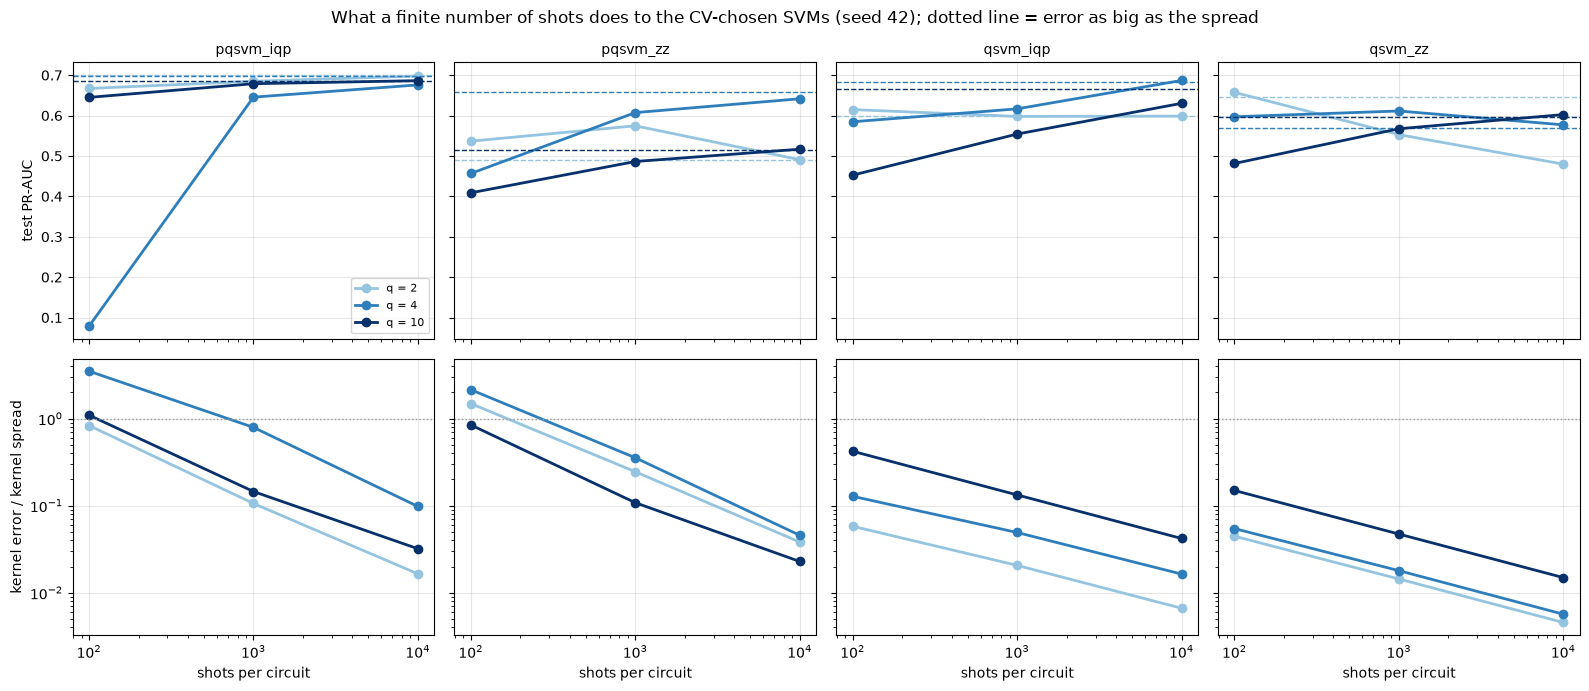

In [136]:
# - PR-AUC and kernel error vs shots, dashed lines are the exact kernel
shot_results = read_results(SETTINGS["shots_file"])
shot_results = shot_results[shot_results["config"] == config_id()].copy()
params = shot_results["params"].map(json.loads)
for key in ["shots", "relative_error", "exact_pr_auc"]:
    shot_results[key] = params.map(lambda p: p[key])
shot_results["q"] = shot_results["q"].astype(int)
shot_results["base_model"] = shot_results["model"].str.rsplit("_", n=1).str[0]

base_models = sorted(shot_results["base_model"].unique())
q_list = sorted(shot_results["q"].unique())
shot_colors = dict(zip(q_list, plt.cm.Blues(np.linspace(0.4, 1, len(q_list)))))
fig, axes = plt.subplots(2, len(base_models), figsize=(4 * len(base_models), 7), sharex=True, sharey="row",
                         squeeze=False)
for col, model in enumerate(base_models):
    for q in q_list:
        d = shot_results[(shot_results["base_model"] == model) & (shot_results["q"] == q)].sort_values("shots")
        if d.empty:
            continue
        axes[0, col].plot(d["shots"], d["pr_auc"], marker="o", markersize=6, linewidth=2, color=shot_colors[q],
                          label=f"q = {q}")
        axes[0, col].axhline(d["exact_pr_auc"].iloc[0], color=shot_colors[q], linestyle="--", linewidth=1)
        axes[1, col].plot(d["shots"], d["relative_error"], marker="o", markersize=6, linewidth=2, color=shot_colors[q])
    axes[0, col].set_title(model, fontsize=10)
    axes[1, col].axhline(1, color="#999999", linestyle=":", linewidth=1)
    axes[1, col].set_yscale("log")
    axes[1, col].set_xlabel("shots per circuit")
for ax in axes.flat:
    ax.set_xscale("log")
    ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("test PR-AUC")
axes[1, 0].set_ylabel("kernel error / kernel spread")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"What a finite number of shots does to the CV-chosen SVMs (seed {SETTINGS['seed']}); "
             "dotted line = error as big as the spread")
fig.tight_layout()
plt.show()

In [137]:
# - noisy simulation on a small subset: exact kernel vs shot noise only vs the fake backend's noise model
nz = SETTINGS["noisy"]
X_train, y_train, X_test, y_test = load_prepared(SETTINGS["seed"])
rng = np.random.default_rng(SETTINGS["seed"])


def pick(y, n_fraud, n_legit):
    return np.sort(np.r_[rng.choice(np.where(y == 1)[0], n_fraud, replace=False),
                         rng.choice(np.where(y == 0)[0], n_legit, replace=False)])


def run_on_backend(template, A, B, simulator):
    # one compute-uncompute circuit per pair (a, b), the kernel value is the share of |0...0> counts
    zeros = "0" * A.shape[1]
    values = []
    for start in range(0, len(A), 1000):
        circuits = [template.assign_parameters({x_symbols: a, y_symbols: b})
                    for a, b in zip(A[start:start + 1000], B[start:start + 1000])]
        result = simulator.run(circuits, shots=nz["shots"], seed_simulator=SETTINGS["seed"]).result()
        values += [result.get_counts(i).get(zeros, 0) / nz["shots"] for i in range(len(circuits))]
    return np.array(values)


tr, te = pick(y_train, nz["n_train_fraud"], nz["n_train_legit"]), pick(y_test, nz["n_test_fraud"], nz["n_test_legit"])
simulator = AerSimulator.from_backend(backend, method="density_matrix")
x_symbols, y_symbols = ParameterVector("x", nz["q"]), ParameterVector("y", nz["q"])
noisy_kernels = {}
if SETTINGS["RUN_NOISY"]:
    for feature_map in SETTINGS["feature_maps"]:
        start = time.time()
        row = svm_cv[(svm_cv["model"] == f"qsvm_{feature_map}") & (svm_cv["q"] == nz["q"])
                     & (svm_cv["seed"] == str(SETTINGS["seed"]))].iloc[0]
        C = json.loads(row["params"])["C"]
        encoder = fit_encoder(X_train, nz["q"])
        A_tr, A_te = encode(encoder, X_train[tr], row["c"]), encode(encoder, X_test[te], row["c"])
        exact_train = fidelity_kernel(A_tr, A_tr, feature_map, SETTINGS["reps"])
        exact_test = fidelity_kernel(A_te, A_tr, feature_map, SETTINGS["reps"])

        template = pass_manager.run(kernel_circuit(x_symbols, y_symbols, feature_map))
        i, j = np.triu_indices(len(tr), 1)
        noisy_train = np.eye(len(tr))
        noisy_train[i, j] = noisy_train[j, i] = run_on_backend(template, A_tr[i], A_tr[j], simulator)
        a, b = np.meshgrid(np.arange(len(te)), np.arange(len(tr)), indexing="ij")
        noisy_test = run_on_backend(template, A_te[a.ravel()], A_tr[b.ravel()], simulator).reshape(len(te), len(tr))

        versions = {"exact": (exact_train, exact_test),
                    "shots": (shot_train_fidelity(exact_train, nz["shots"], rng), shot_fidelity(exact_test, nz["shots"], rng)),
                    "noisy": (noisy_train, noisy_test)}
        noisy_kernels[feature_map] = {name: K_test for name, (_, K_test) in versions.items()}
        for name, (K_train, K_test) in versions.items():
            model = fit_classifier("svm", K_train, y_train[tr], C)
            scores = predict("svm", model, K_test, y_train[tr])
            # the subset has far more fraud than real life, so PR-AUC is weighted back to the true rate as in CV
            metrics = {**evaluate(y_test[te], scores), "pr_auc": validation_ap(y_test[te], scores)}
            errors = np.r_[(K_train - exact_train)[i, j], (K_test - exact_test).ravel()]
            save_result(f"qsvm_{feature_map}_{name}", nz["q"], SETTINGS["seed"],
                        {"C": C, "shots": nz["shots"], "backend": SETTINGS["backend"],
                         "kernel_error": np.abs(errors).mean(),
                         "relative_frobenius": np.linalg.norm(errors) / np.linalg.norm(np.r_[exact_train[i, j], exact_test.ravel()]),
                         "pr_auc_weighted": True},
                        metrics, len(tr), len(te), c=row["c"], file=SETTINGS["noisy_file"])
        print(f"{feature_map}: {len(i) + exact_test.size:,} circuits in {time.time() - start:.0f} s")

noisy_results = read_results(SETTINGS["noisy_file"])
noisy_results = noisy_results[noisy_results["config"] == config_id()].copy()
params = noisy_results["params"].map(json.loads)
for key in ["kernel_error", "relative_frobenius"]:
    noisy_results[key] = params.map(lambda p: p[key])
print(f"q = {nz['q']}, {len(tr)} training and {len(te)} test rows, {nz['shots']} shots, "
      f"PR-AUC weighted to the real fraud rate ({nz['n_test_fraud']} test frauds, so it is noisy)")
print(noisy_results[["model", "c", "pr_auc", "roc_auc", "recall_fpr1", "kernel_error", "relative_frobenius"]]
      .round(3).to_string(index=False))

zz: 46,740 circuits in 181 s
iqp: 46,740 circuits in 424 s
q = 4, 120 training and 330 test rows, 1000 shots, PR-AUC weighted to the real fraud rate (30 test frauds, so it is noisy)
         model   c  pr_auc  roc_auc  recall_fpr1  kernel_error  relative_frobenius
 qsvm_zz_exact 0.1   0.801    0.866        0.800         0.000               0.000
 qsvm_zz_shots 0.1   0.801    0.873        0.800         0.003               0.006
 qsvm_zz_noisy 0.1   0.801    0.881        0.800         0.125               0.134
qsvm_iqp_exact 0.1   0.802    0.915        0.800         0.000               0.000
qsvm_iqp_shots 0.1   0.801    0.906        0.800         0.001               0.003
qsvm_iqp_noisy 0.1   0.443    0.849        0.433         0.266               0.268


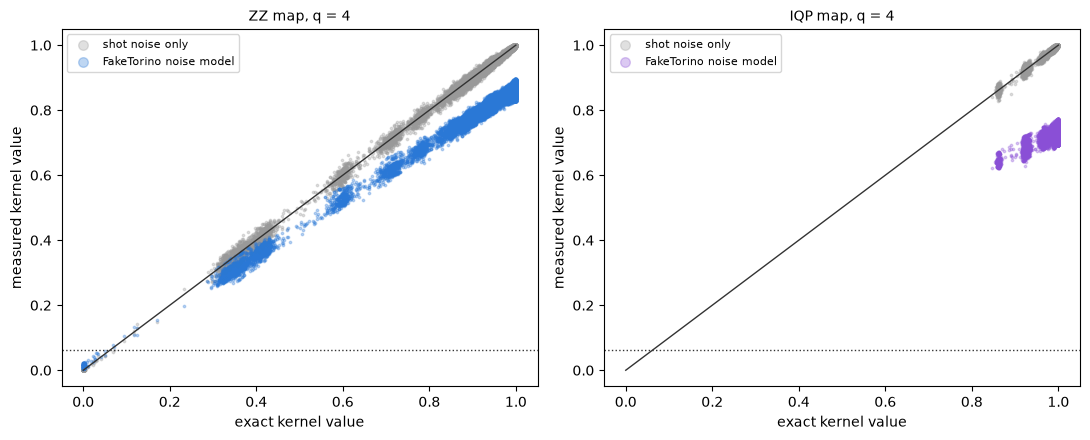

In [138]:
# - measured vs exact kernel values on the test subset, noise pulls everything towards 1 / 2^q
if noisy_kernels:
    fig, axes = plt.subplots(1, len(noisy_kernels), figsize=(11, 4.5), squeeze=False)
    for ax, (feature_map, K) in zip(axes[0], noisy_kernels.items()):
        ax.scatter(K["exact"].ravel(), K["shots"].ravel(), s=3, alpha=0.3, color="#999999", label="shot noise only")
        ax.scatter(K["exact"].ravel(), K["noisy"].ravel(), s=3, alpha=0.3, color=map_colors[feature_map],
                   label=f"{SETTINGS['backend']} noise model")
        ax.plot([0, 1], [0, 1], color="#333333", linewidth=1)
        ax.axhline(2.0 ** -nz["q"], color="#333333", linestyle=":", linewidth=1)
        ax.set_xlabel("exact kernel value")
        ax.set_ylabel("measured kernel value")
        ax.set_title(f"{feature_map.upper()} map, q = {nz['q']}", fontsize=10)
        ax.legend(fontsize=8, markerscale=4)
    fig.tight_layout()
    plt.show()

### Hardware findings

To be written after the run: circuit cost vs q, how many shots it takes before PR-AUC stops dropping, and how far the fake-backend kernel is from the exact one.

## 12. Fewer false alarms: more data and fraud weight

Fraud is 0.17% of transactions, so even flagging 1% of legit ones gives about 6 false alarms per fraud. Here the two CV-best models are refitted on seed 42 with more legit training rows and different fraud weights, to see which one cuts false alarms.

In [139]:
# - false alarms needed to catch a given share of the test frauds, and the precision at that point
def false_alarms_at_recall(y, scores, target):
    fpr, tpr, _ = roc_curve(y, scores)
    i = np.argmax(tpr >= target)
    false_alarms = fpr[i] * (y == 0).sum()
    caught = tpr[i] * (y == 1).sum()
    return int(round(false_alarms)), caught / (caught + false_alarms)


def class_weight(weight):
    return "balanced" if weight == "balanced" else {0: 1, 1: weight}


assert false_alarms_at_recall(np.array([0, 0, 1, 1]), np.array([0.1, 0.2, 0.8, 0.9]), 1.0) == (0, 1.0)
assert false_alarms_at_recall(np.array([0, 0, 1, 1]), np.array([0.1, 0.9, 0.8, 0.2]), 1.0) == (1, 2 / 3)

In [140]:
# - for each model, training size and fraud weight: tune C on CV, fit, score the full test set
def tune_C(kernel, folds, y_train, factor, weight):
    fold_kernels = []
    for tr, va, A_fit, A_eval in folds:
        gamma = None if factor is None else factor * default_gamma(A_fit)
        fold_kernels.append((kernel_block(kernel, A_fit, A_fit, gamma), kernel_block(kernel, A_eval, A_fit, gamma)))
    best = None
    for C in SETTINGS["C_values"]:
        aps = []
        for (tr, va, _, _), (K_fit, K_eval) in zip(folds, fold_kernels):
            model = SVC(kernel="precomputed", C=C, class_weight=class_weight(weight)).fit(K_fit, y_train[tr])
            aps.append(validation_ap(y_train[va], model.decision_function(K_eval)))
        if best is None or np.mean(aps) > best[1]:
            best = (C, np.mean(aps))
    return best


def weighted_svm_scores(kernel, feature_map, final, y_train, factor, weight, C):
    A_train, test_angles = final
    gamma = None if factor is None else factor * default_gamma(A_train)
    model = SVC(kernel="precomputed", C=C, class_weight=class_weight(weight))
    model.fit(kernel_block(kernel, A_train, A_train, gamma), y_train)
    scores = []
    step = SETTINGS["kernel_chunk"]
    for start in range(0, len(test_angles), step):
        A_test = kernel_input(kernel, feature_map, test_angles[start:start + step])
        scores.append(model.decision_function(kernel_block(kernel, A_test, A_train, gamma)))
    return np.concatenate(scores)


if SETTINGS["RUN_MORE_DATA"]:
    old = read_results(SETTINGS["more_data_file"])
    done = set(old.loc[old["config"] == config_id(), "model"])
    for kernel, (base_model, q) in best.items():
        row = svm_cv[(svm_cv["model"] == base_model) & (svm_cv["q"] == q) & (svm_cv["seed"] == str(SETTINGS["seed"]))].iloc[0]
        feature_map, q, c = base_model.split("_")[-1], int(q), row["c"]
        factor = None
        if kernel == "projected":
            # keep the gamma factor the sweep picked, so only data size and weight change
            X_train, _, _, _ = load_prepared(SETTINGS["seed"])
            F = kernel_input(kernel, feature_map, fit_and_transform(X_train, X_train[:1], q, c)[0])
            factor = json.loads(row["params"])["gamma"] / default_gamma(F)
        for n in SETTINGS["learning_sizes"]:
            todo = [w for w in SETTINGS["fraud_weights"] if f"{base_model}_n{n}_w{w}" not in done]
            if not todo:
                continue
            X_train, y_train, X_test, y_test = load_prepared(SETTINGS["seed"], n)
            folds, final = kernel_inputs(kernel, feature_map, X_train, y_train, X_test, q, c)
            for weight in todo:
                start = time.time()
                C, cv_ap = tune_C(kernel, folds, y_train, factor, weight)
                scores = weighted_svm_scores(kernel, feature_map, final, y_train, factor, weight, C)
                metrics = evaluate(y_test, scores)
                false_alarms, precision = false_alarms_at_recall(y_test, scores, SETTINGS["target_recall"])
                save_result(f"{base_model}_n{n}_w{weight}", q, SETTINGS["seed"],
                            {"kernel": kernel, "base_model": base_model, "fraud_weight": str(weight), "C": C,
                             "gamma_factor": factor, "cv_pr_auc": cv_ap, "false_alarms": false_alarms,
                             "precision": precision, "target_recall": SETTINGS["target_recall"],
                             "seconds": round(time.time() - start, 1)},
                            metrics, n, len(y_test), c=c, file=SETTINGS["more_data_file"])
                print(f"{base_model} n={n} weight={weight} C={C}: PR-AUC {metrics['pr_auc']:.3f}, "
                      f"{false_alarms} false alarms to catch {SETTINGS['target_recall']:.0%} of frauds "
                      f"({time.time() - start:.0f} s)")
            folds = final = None
    print(f"the n={SETTINGS['n_train']}, weight=balanced runs should match the sweep: "
          + ", ".join(f"{m} {svm_cv[(svm_cv['model'] == m) & (svm_cv['q'] == q) & (svm_cv['seed'] == str(SETTINGS['seed']))]['pr_auc'].iloc[0]:.3f}"
                      for m, q in best.values()))

the n=5000, weight=balanced runs should match the sweep: qsvm_iqp 0.665, pqsvm_iqp 0.686


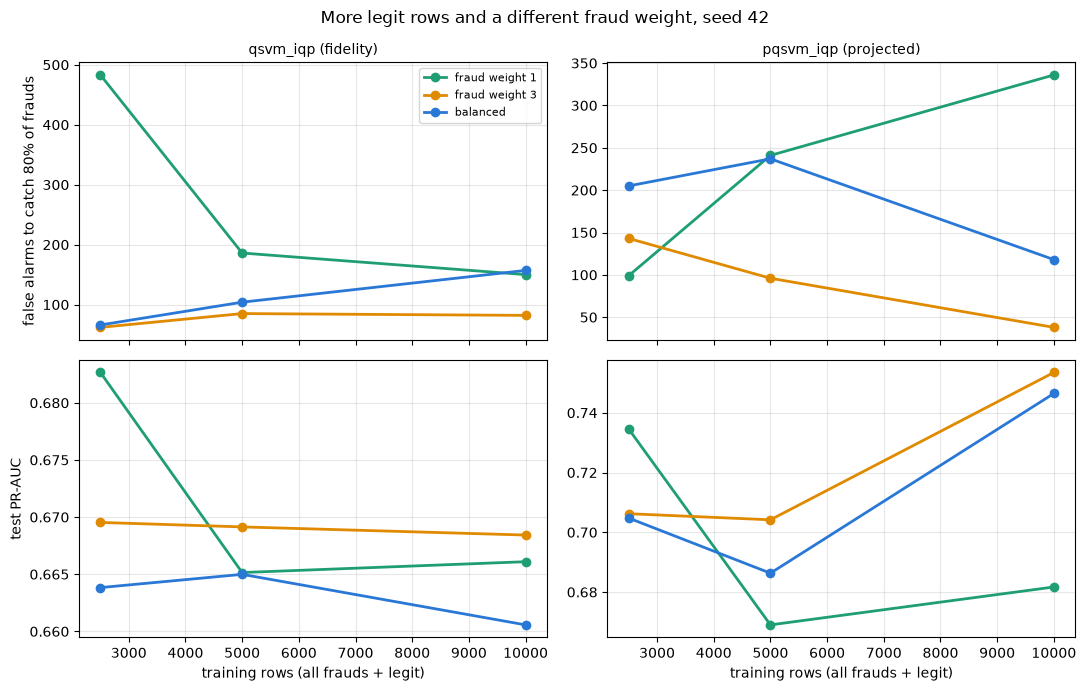

In [141]:
# - false alarms and PR-AUC vs training size, one line per fraud weight
more = read_results(SETTINGS["more_data_file"])
more = more[more["config"] == config_id()].copy()
params = more["params"].map(json.loads)
for key in ["kernel", "base_model", "fraud_weight", "C", "cv_pr_auc", "false_alarms", "precision"]:
    more[key] = params.map(lambda p: p[key])

weight_colors = {"1": "#1f9e74", "3": "#e08a00", "balanced": "#2a78d6"}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, squeeze=False)
for col, kernel in enumerate(["fidelity", "projected"]):
    d_kernel = more[more["kernel"] == kernel]
    for weight, d in d_kernel.groupby("fraud_weight"):
        d = d.sort_values("n_train")
        label = "balanced" if weight == "balanced" else f"fraud weight {weight}"
        axes[0, col].plot(d["n_train"], d["false_alarms"], marker="o", markersize=6, linewidth=2,
                          color=weight_colors[weight], label=label)
        axes[1, col].plot(d["n_train"], d["pr_auc"], marker="o", markersize=6, linewidth=2, color=weight_colors[weight])
    title = d_kernel["base_model"].iloc[0] if len(d_kernel) else kernel
    axes[0, col].set_title(f"{title} ({kernel})", fontsize=10)
    axes[1, col].set_xlabel("training rows (all frauds + legit)")
for ax in axes.flat:
    ax.grid(alpha=0.3)
axes[0, 0].set_ylabel(f"false alarms to catch {SETTINGS['target_recall']:.0%} of frauds")
axes[1, 0].set_ylabel("test PR-AUC")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"More legit rows and a different fraud weight, seed {SETTINGS['seed']}")
fig.tight_layout()
plt.show()

In [142]:
# - the CV-chosen fraud weight for each size, next to the current setup (5000 rows, balanced)
chosen = more.sort_values("cv_pr_auc", ascending=False).drop_duplicates(["kernel", "n_train"])
current = more[(more["n_train"].astype(int) == SETTINGS["n_train"]) & (more["fraud_weight"] == "balanced")]
current = current.set_index("kernel")["false_alarms"]
chosen["vs current"] = chosen["false_alarms"] - chosen["kernel"].map(current)
columns = ["kernel", "base_model", "n_train", "fraud_weight", "C", "cv_pr_auc", "pr_auc", "false_alarms", "precision",
           "vs current"]
print(f"weight picked by CV for each training size; false alarms are on the {int(more['n_test'].iloc[0]):,}-row test set "
      f"at {SETTINGS['target_recall']:.0%} recall (picked on test labels, so they describe the model)")
print(chosen[columns].sort_values(["kernel", "n_train"]).round(3).to_string(index=False))

weight picked by CV for each training size; false alarms are on the 56,746-row test set at 80% recall (picked on test labels, so they describe the model)
   kernel base_model  n_train fraud_weight    C  cv_pr_auc  pr_auc  false_alarms  precision  vs current
 fidelity   qsvm_iqp     2500     balanced 10.0      0.716   0.664            66      0.535         -38
 fidelity   qsvm_iqp     5000            3 10.0      0.845   0.669            85      0.472         -19
 fidelity   qsvm_iqp    10000            3 10.0      0.811   0.668            82      0.481         -22
projected  pqsvm_iqp     2500            3 10.0      0.769   0.706           143      0.347         -94
projected  pqsvm_iqp     5000            3  1.0      0.842   0.704            96      0.442        -141
projected  pqsvm_iqp    10000            3  1.0      0.765   0.753            38      0.667        -199
